In [ ]:
# import os
# from google.colab import drive

# # Ensure the mount point is clean before attempting to mount
# if os.path.exists('/content/drive'):
#     !rm -rf /content/drive/*
#     !rmdir /content/drive

# drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class eca_layer(nn.Module):
    def __init__(self, channel, k_size=3):
        super(eca_layer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1)//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        y = self.avg_pool(x)
        y = self.conv(y.transpose(-1, -2)).transpose(-1, -2)
        y = self.sigmoid(y)
        return x * y.expand_as(x)


In [4]:
from tqdm import tqdm
import os
import torch
import torch.nn as nn
import pickle

from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.models import densenet121, DenseNet121_Weights
import os
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)

class FeatureExtractorSwin(nn.Module):
    def __init__(self):
        super().__init__()

        base = swin_t(weights=Swin_T_Weights.DEFAULT)

        self.features = base.features
        self.norm = base.norm
        self.out_dim = base.head.in_features

    def forward(self, x):
        x = self.features(x)
        x = self.norm(x)

        # (B, H, W, C) -> (B, C)
        x = x.mean(dim=(1, 2))

        return x

class FeatureExtractorResNet(nn.Module):
    def __init__(self):
        super().__init__()
        base = resnet50(weights=ResNet50_Weights.DEFAULT)
        self.features = nn.Sequential(*list(base.children())[:-1])  # remove FC
        self.out_dim = base.fc.in_features

    def forward(self, x):
        x = self.features(x)
        return x.view(x.size(0), -1)

# class FeatureExtractorEffNet(nn.Module):
#     def __init__(self):
#         super().__init__()
#         base = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
#         self.features = base.features
#         self.pool = nn.AdaptiveAvgPool2d(1)
#         self.out_dim = base.classifier[1].in_features

#     def forward(self, x):
#         x = self.features(x)
#         x = self.pool(x)
#         return x.view(x.size(0), -1)

class FeatureExtractorDenseNet(nn.Module):
    def __init__(self):
        super().__init__()
        base = densenet121(weights=DenseNet121_Weights.DEFAULT)
        self.features = base.features
        self.norm = nn.ReLU(inplace=True)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = base.classifier.in_features

    def forward(self, x):
        x = self.features(x)
        x = self.norm(x)
        x = self.pool(x)
        return x.view(x.size(0), -1)


In [5]:
class EnsembleFeatureECA(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet = FeatureExtractorResNet()
        self.swinT = FeatureExtractorSwin()
        self.densenet = FeatureExtractorDenseNet()

        # Freeze feature extractors
        for m in [self.resnet, self.swinT, self.densenet]:
            for p in m.parameters():
                p.requires_grad = False

        # Total feature dimension
        total_dim = self.resnet.out_dim + self.swinT.out_dim + self.densenet.out_dim

        # ECA applied on fused features
        self.eca = eca_layer(total_dim)

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        f1 = self.resnet(x)
        f2 = self.swinT(x)
        f3 = self.densenet(x)
        fused = torch.cat([f1, f2, f3], dim=1)
        fused = fused.unsqueeze(-1)  # (B, C, 1)
        fused = self.eca(fused).squeeze(-1)
        out = self.classifier(fused)
        return out


In [6]:
import os
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"
checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/Ensemble"

os.makedirs(checkpoint_dir, exist_ok=True)

# Paths to pre-trained model weights

resnet_weights_path = "/content/drive/MyDrive/Classification/Weights/ResNet_50/epoch_50_weights.pth"
swinT_weights_path = "/content/drive/MyDrive/Classification/Weights/Swin_Transformers/epoch_15_weights.pth"
densenet_weights_path = "/content/drive/MyDrive/Classification/Weights/DenseNet121/epoch_25_weights.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# ECA Module
# ------------------------
class ECALayer(nn.Module):
    def __init__(self, channel, k_size=3):
        super(ECALayer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1) // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x: (B, C)
        b, c = x.size()
        y = x.unsqueeze(-1)  # (B, C, 1)
        y = y.transpose(1, 2)  # (B, 1, C)
        y = self.conv(y)  # (B, 1, C)
        y = self.sigmoid(y)  # (B, 1, C)
        y = y.transpose(1, 2).squeeze(-1)  # (B, C)
        return x * y

# ------------------------
# Feature Extractor Models
# ------------------------
class ResNet50FeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        weights = ResNet50_Weights.DEFAULT
        self.model = resnet50(weights=weights)
        in_features = self.model.fc.in_features
        self.model.fc = nn.Identity()  # Remove final layer
        self.feature_dim = in_features

    def forward(self, x):
        return self.model(x)

import torch.nn as nn
from torchvision.models import swin_t, Swin_T_Weights


class SwinFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        weights = Swin_T_Weights.DEFAULT
        self.model = swin_t(weights=weights)
        in_features = self.model.head.in_features
        self.model.head = nn.Identity()  # Remove final classification layer
        self.feature_dim = in_features

    def forward(self, x):
        return self.model(x)

class DenseNetFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.model = densenet121(weights=weights)
        in_features = self.model.classifier.in_features
        self.model.classifier = nn.Identity()  # Remove final layer
        self.feature_dim = in_features

    def forward(self, x):
        return self.model(x)

# ------------------------
# Ensemble Model with ECA
# ------------------------
class EnsembleWithECA(nn.Module):
    def __init__(self, resnet_path, swinT_path, densenet_path):
        super().__init__()

        # Load feature extractors
        self.resnet = ResNet50FeatureExtractor()
        self.swinT = SwinFeatureExtractor()
        self.densenet = DenseNetFeatureExtractor()

        # Load pre-trained weights and freeze
        self._load_pretrained_weights(resnet_path, swinT_path, densenet_path)
        self._freeze_feature_extractors()

        # Calculate total feature dimension
        total_features = (self.resnet.feature_dim +
                         self.swinT.feature_dim +
                         self.densenet.feature_dim)

        # ECA layer
        self.eca = ECALayer(total_features, k_size=3)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(total_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def _load_pretrained_weights(self, resnet_path, swinT_path, densenet_path):
        # Load ResNet weights
        resnet_state = torch.load(resnet_path, map_location='cpu')
        # Remove fc layer weights from state dict
        resnet_state = {k: v for k, v in resnet_state.items() if not k.startswith('model.fc')}
        self.resnet.load_state_dict(resnet_state, strict=False)

        # Load EfficientNet weights
        swinT_state = torch.load(swinT_path, map_location='cpu')
        swinT_state = {k: v for k, v in swinT_state.items() if not k.startswith('model.classifier')}
        self.swinT.load_state_dict(swinT_state, strict=False)

        # Load DenseNet weights
        densenet_state = torch.load(densenet_path, map_location='cpu')
        densenet_state = {k: v for k, v in densenet_state.items() if not k.startswith('model.classifier')}
        self.densenet.load_state_dict(densenet_state, strict=False)

    def _freeze_feature_extractors(self):
        for param in self.resnet.parameters():
            param.requires_grad = False
        for param in self.swinT.parameters():
            param.requires_grad = False
        for param in self.densenet.parameters():
            param.requires_grad = False

    def forward(self, x):
        # Extract features from all models
        resnet_features = self.resnet(x)
        swinT_features = self.swinT(x)
        densenet_features = self.densenet(x)

        # Concatenate features
        combined_features = torch.cat([resnet_features, swinT_features, densenet_features], dim=1)

        # Apply ECA
        attended_features = self.eca(combined_features)

        # Classify
        output = self.classifier(attended_features)
        return output

# ------------------------
# Model & Transform
# ------------------------
weights = ResNet50_Weights.DEFAULT
transform = weights.transforms()

model = EnsembleWithECA(resnet_weights_path, swinT_weights_path, densenet_weights_path).to(device)

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer (only trainable parameters)
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")



Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/Ensemble


In [7]:
# # ------------------------
# # Training Loop
# # ------------------------
# for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):
#     model.train()
#     running_loss, correct, total = 0.0, 0, 0

#     for images, labels in train_loader:
#         images = images.to(device)
#         labels = labels.float().unsqueeze(1).to(device)

#         optimizer.zero_grad()
#         outputs = model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * labels.size(0)
#         preds = (outputs > 0.5).float()
#         correct += (preds == labels).sum().item()
#         total += labels.size(0)

#     train_loss = running_loss / total
#     train_acc = correct / total

#     # Validation
#     model.eval()
#     val_loss, val_correct, val_total = 0.0, 0, 0

#     with torch.no_grad():
#         for images, labels in val_loader:
#             images = images.to(device)
#             labels = labels.float().unsqueeze(1).to(device)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             val_loss += loss.item() * labels.size(0)
#             preds = (outputs > 0.5).float()
#             val_correct += (preds == labels).sum().item()
#             val_total += labels.size(0)

#     val_loss /= val_total
#     val_acc = val_correct / val_total

#     # Save best model
#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         torch.save(model.state_dict(), os.path.join(checkpoint_dir, "best_ensemble_weights.pth"))

#     # Save model and history every 5 epochs
#     if epoch % 5 == 0:
#         torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"epoch_{epoch}_ensemble_weights.pth"))
#         history["train_loss"].append(train_loss)
#         history["train_acc"].append(train_acc)
#         history["val_loss"].append(val_loss)
#         history["val_acc"].append(val_acc)

#         with open(os.path.join(checkpoint_dir, "ensemble_history.pkl"), "wb") as f:
#             pickle.dump(history, f)

#     print(f"Epoch {epoch:2d}: "
#           f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
#           f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_ensemble_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_ensemble_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_ensemble_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "ensemble_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.0326)


Epochs:   2%|▏         | 1/50 [01:11<58:39, 71.83s/it]

Epoch  1: Train Loss: 0.0611, Train Acc: 0.9827, Val Loss: 0.0326, Val Acc: 0.9915


Epochs:   4%|▍         | 2/50 [02:20<55:54, 69.89s/it]

...

Epoch 48: Train Loss: 0.0032, Train Acc: 0.9992, Val Loss: 0.2033, Val Acc: 0.9949


Epochs:  98%|█████████▊| 49/50 [1:03:44<01:11, 71.19s/it]

Epoch 49: Train Loss: 0.0033, Train Acc: 0.9987, Val Loss: 0.3428, Val Acc: 0.9949


Epochs: 100%|██████████| 50/50 [1:04:46<00:00, 77.73s/it]

Epoch 50: Train Loss: 0.0031, Train Acc: 0.9983, Val Loss: 0.2007, Val Acc: 0.9932

TRAINING COMPLETED
Best Validation Loss: 0.0195
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/Ensemble


In [10]:
import os
import torch
import numpy as np
import pandas as pd
from torchvision.io import read_image
from tqdm import tqdm

# ----------------------
# Setup
# ----------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths to pre-trained model weights
resnet_weights_path = "/content/drive/MyDrive/Classification/Weights/ResNet_50/epoch_50_weights.pth"
swinT_weights_path = "/content/drive/MyDrive/Classification/Weights/Swin_Transformers/epoch_15_weights.pth"
densenet_weights_path = "/content/drive/MyDrive/Classification/Weights/DenseNet121/epoch_25_weights.pth"

# Load ensemble model
model = EnsembleWithECA(resnet_weights_path, swinT_weights_path, densenet_weights_path).to(device)

# Load trained ensemble weights
ensemble_weights_path = "/content/drive/MyDrive/Classification/Weights/Ensemble/epoch_09_ensemble_weights.pth"
model.load_state_dict(torch.load(ensemble_weights_path, map_location=device))
model.eval()

# Transform
weights = ResNet50_Weights.DEFAULT
transform = weights.transforms()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []
all_predictions = []
all_labels = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        if not os.path.exists(folder):
            print(f"Warning: Folder {folder} does not exist. Skipping...")
            continue

        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            path = os.path.join(folder, fname)

            try:
                image = read_image(path).float() / 255.0
                image = transform(image).unsqueeze(0).to(device)

                output = model(image)
                pred = 1 if output.item() > 0.5 else 0

                # Store predictions and labels
                all_predictions.append(pred)
                all_labels.append(label)

                # Accuracy for deviation
                correct = (pred == label)
                accuracies.append(int(correct))

                # Confusion matrix components
                if pred == 1 and label == 1:
                    TP += 1
                elif pred == 1 and label == 0:
                    FP += 1
                elif pred == 0 and label == 0:
                    TN += 1
                elif pred == 0 and label == 1:
                    FN += 1
            except Exception as e:
                print(f"Error processing {fname}: {e}")
                continue

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
precision = TP / (TP + FP) if (TP + FP) else 0
f1_score = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) else 0
deviation = np.std(accuracies) if accuracies else 0

# ----------------------
# Print Results
# ----------------------
print("\n" + "="*50)
print("ENSEMBLE MODEL TEST RESULTS")
print("="*50)
print(f"Total Images Tested: {total}")
print(f"\nConfusion Matrix:")
print(f"  True Positives (TP):  {TP}")
print(f"  False Positives (FP): {FP}")
print(f"  True Negatives (TN):  {TN}")
print(f"  False Negatives (FN): {FN}")
print(f"\nPerformance Metrics:")
print(f"  Accuracy:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  Sensitivity:  {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"  Specificity:  {specificity:.4f} ({specificity*100:.2f}%)")
print(f"  Precision:    {precision:.4f} ({precision*100:.2f}%)")
print(f"  F1-Score:     {f1_score:.4f}")
print(f"  Accuracy StdDev: {deviation:.4f}")
print("="*50 + "\n")

# ----------------------
# Save CSV
# ----------------------
results = {
    'Model': ['Ensemble (ResNet50 + SwinTransformer + DenseNet121 + ECA)'],
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Total': [total],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Precision': [round(precision, 4)],
    'F1-Score': [round(f1_score, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
output_csv = "/content/drive/MyDrive/Classification/Results/Ensemble/ensemble_epoch_9.csv"
df.to_csv(output_csv, index=False)
print(f"Results saved to '{output_csv}'")

# ----------------------
# Optional: Save detailed predictions
# ----------------------
detailed_results = {
    'Prediction': all_predictions,
    'True_Label': all_labels,
    'Correct': [int(p == l) for p, l in zip(all_predictions, all_labels)]
}
detailed_df = pd.DataFrame(detailed_results)
detailed_csv = "/content/drive/MyDrive/Classification/Results/Ensemble/Ensemble_ECA_detailed_predictions_epoch9.csv"
detailed_df.to_csv(detailed_csv, index=False)
print(f"Detailed predictions saved to '{detailed_csv}'")

Evaluating b_cancer: 100%|██████████| 164/164 [00:08<00:00, 19.66it/s]



ENSEMBLE MODEL TEST RESULTS
Total Images Tested: 328

Confusion Matrix:
  True Positives (TP):  162
  False Positives (FP): 2
  True Negatives (TN):  162
  False Negatives (FN): 2

Performance Metrics:
  Accuracy:     0.9878 (98.78%)
  Sensitivity:  0.9878 (98.78%)
  Specificity:  0.9878 (98.78%)
  Precision:    0.9878 (98.78%)
  F1-Score:     0.9878
  Accuracy StdDev: 0.1098

Results saved to '/content/drive/MyDrive/Classification/Results/Ensemble/ensemble_epoch_9.csv'
Detailed predictions saved to '/content/drive/MyDrive/Classification/Results/Ensemble/Ensemble_ECA_detailed_predictions_epoch9.csv'


Device: cuda

✅ Ensemble weights loaded successfully.


Evaluating b_cancer: 100%|██████████| 164/164 [00:11<00:00, 13.75it/s]



ENSEMBLE MODEL TEST RESULTS
Total Images Tested: 328

Confusion Matrix:
  True Positives (TP):  162
  False Positives (FP): 2
  True Negatives (TN):  162
  False Negatives (FN): 2

Performance Metrics:
  Accuracy:          0.9878 (98.78%)
  Sensitivity:       0.9878 (98.78%)
  Specificity:       0.9878 (98.78%)
  Precision:         0.9878 (98.78%)
  F1-Score:          0.9878
  Accuracy StdDev:   0.1098

Calibration Metrics:
  Brier Score:       0.0123
  ECE:               0.0124
  MCE:               0.1740
  ROC-AUC:            0.9822

95% Confidence Intervals:
  Accuracy:          0.9691 - 0.9952
  Sensitivity:       0.9566 - 0.9966
  Specificity:       0.9566 - 0.9966
  Precision:         0.9566 - 0.9966
  F1:                0.9747 - 1.0000
  ROC-AUC:           0.9633 - 1.0000
  Brier Score:       0.0003 - 0.0245

✅ Results saved to:
/content/drive/MyDrive/Classification/Results/Ensemble/ensemble_epoch_9_calibration_metrics.csv
✅ Detailed predictions saved to:
/content/drive/MyDrive

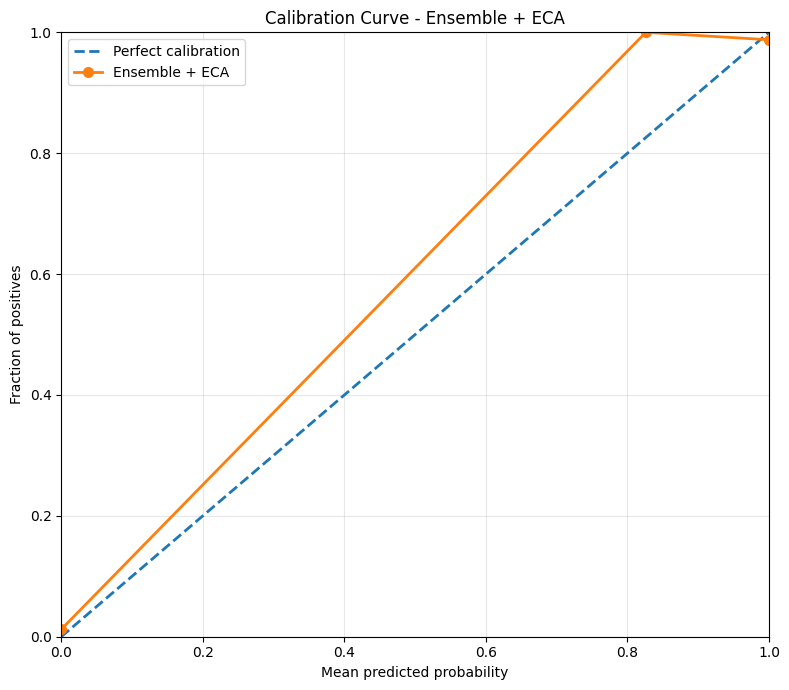

✅ Calibration curve saved to:
/content/drive/MyDrive/Classification/Results/Ensemble/ensemble_epoch_9_calibration_curve.png


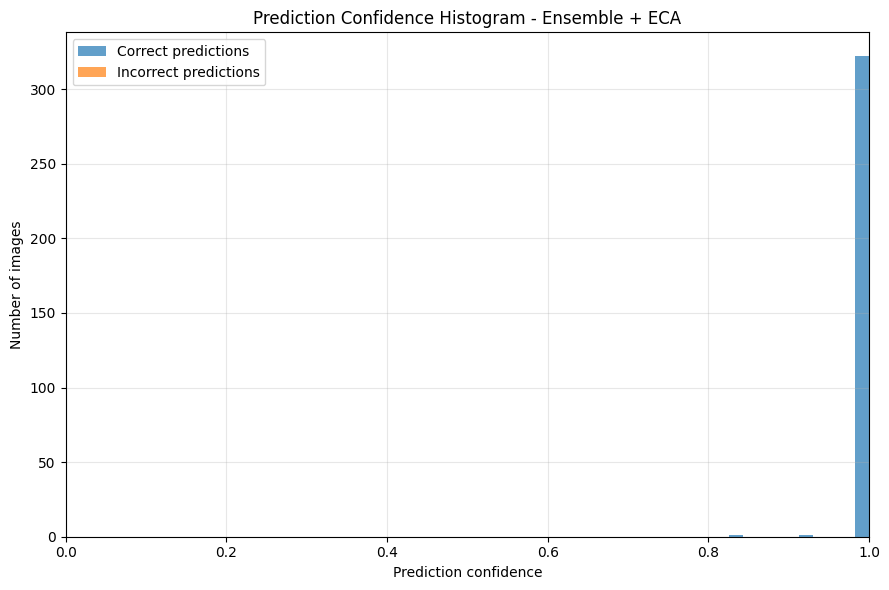

✅ Confidence histogram saved to:
/content/drive/MyDrive/Classification/Results/Ensemble/ensemble_epoch_9_confidence_histogram.png

CALIBRATION ANALYSIS COMPLETE

ECE        : 0.0124
MCE        : 0.1740
Brier      : 0.0123
ROC-AUC    : 0.9822

All results have been saved.


In [9]:
# ================================================================
# ENSEMBLE MODEL PERFORMANCE + CALIBRATION ANALYSIS
#
# Model:
# ResNet50 + Swin Transformer + DenseNet121 + ECA
#
# Includes:
#   1. Accuracy
#   2. Sensitivity
#   3. Specificity
#   4. Precision
#   5. F1-score
#   6. Accuracy StdDev
#   7. ROC-AUC
#   8. Brier Score
#   9. Expected Calibration Error (ECE)
#  10. Maximum Calibration Error (MCE)
#  11. Calibration curve
#  12. Confidence histogram
#  13. 95% Confidence Intervals
#  14. Detailed prediction CSV
#  15. Calibration-bin CSV
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import os
import torch
import numpy as np
import pandas as pd

from torchvision.io import read_image
from torchvision.models import ResNet50_Weights

from tqdm import tqdm

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    precision_score,
    f1_score
)

from sklearn.calibration import calibration_curve


# ================================================================
# 2. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ================================================================
# 3. MODEL WEIGHT PATHS
# ================================================================

resnet_weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "ResNet_50/"
    "epoch_50_weights.pth"
)

swinT_weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Swin_Transformers/"
    "epoch_15_weights.pth"
)

densenet_weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "DenseNet121/"
    "epoch_25_weights.pth"
)


# ================================================================
# 4. LOAD ENSEMBLE MODEL
# ================================================================

model = EnsembleWithECA(
    resnet_weights_path,
    swinT_weights_path,
    densenet_weights_path
).to(device)


# ================================================================
# 5. LOAD TRAINED ENSEMBLE WEIGHTS
# ================================================================

ensemble_weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Ensemble/"
    "epoch_09_ensemble_weights.pth"
)

ensemble_state = torch.load(
    ensemble_weights_path,
    map_location=device
)

model.load_state_dict(
    ensemble_state
)

model.eval()

print(
    "\n✅ Ensemble weights loaded successfully."
)


# ================================================================
# 6. TRANSFORM
# ================================================================

weights = ResNet50_Weights.DEFAULT

transform = weights.transforms()


# ================================================================
# 7. TEST DATA
# ================================================================

test_root = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2"
)

class_map = {
    'a_non_cancer': 0,
    'b_cancer': 1
}


# ================================================================
# 8. INITIALIZE CONFUSION MATRIX
# ================================================================

TP = 0
FP = 0
TN = 0
FN = 0


# ================================================================
# 9. STORAGE
# ================================================================

accuracies = []

all_predictions = []

all_labels = []

all_probabilities = []

all_paths = []


# ================================================================
# 10. EVALUATION LOOP
#
# The prediction procedure is kept the same as your original code.
# ================================================================

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"Warning: Folder {folder} "
                f"does not exist. Skipping..."
            )

            continue


        for fname in tqdm(
            os.listdir(folder),
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (
                    '.png',
                    '.jpg',
                    '.jpeg'
                )
            ):
                continue


            path = os.path.join(
                folder,
                fname
            )


            try:

                # ------------------------------------------------
                # Load image
                # ------------------------------------------------

                image = (
                    read_image(path)
                    .float()
                    / 255.0
                )


                # ------------------------------------------------
                # Apply transform
                # ------------------------------------------------

                image = (
                    transform(image)
                    .unsqueeze(0)
                    .to(device)
                )


                # ------------------------------------------------
                # Ensemble prediction
                # ------------------------------------------------

                output = model(image)


                # ------------------------------------------------
                # Probability
                #
                # Your classifier ends with Sigmoid(), therefore
                # output.item() is already in [0, 1].
                # ------------------------------------------------

                probability = output.item()


                # ------------------------------------------------
                # Classification threshold
                # ------------------------------------------------

                pred = (
                    1
                    if probability > 0.5
                    else 0
                )


                # ------------------------------------------------
                # Store predictions
                # ------------------------------------------------

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_probabilities.append(
                    probability
                )

                all_paths.append(
                    path
                )


                # ------------------------------------------------
                # Accuracy deviation
                # ------------------------------------------------

                correct = (
                    pred == label
                )

                accuracies.append(
                    int(correct)
                )


                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1


            except Exception as e:

                print(
                    f"Error processing {fname}: {e}"
                )

                continue


# ================================================================
# 11. CONVERT TO NUMPY
# ================================================================

y_true = np.asarray(
    all_labels,
    dtype=np.int64
)

y_pred = np.asarray(
    all_predictions,
    dtype=np.int64
)

y_prob = np.asarray(
    all_probabilities,
    dtype=np.float64
)

accuracies = np.asarray(
    accuracies,
    dtype=np.int64
)


# ================================================================
# 12. ORIGINAL PERFORMANCE METRICS
#
# These formulas are kept exactly as in your code.
# ================================================================

total = (
    TP +
    FP +
    TN +
    FN
)


accuracy = (
    (TP + TN) / total
    if total
    else 0
)


sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)


specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)


precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)


f1_score_value = (
    2 * (
        precision *
        sensitivity
    )
    /
    (
        precision +
        sensitivity
    )
    if (
        precision +
        sensitivity
    )
    else 0
)


deviation = (
    np.std(accuracies)
    if len(accuracies) > 0
    else 0
)


# ================================================================
# 13. ROC-AUC
# ================================================================

try:

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

except ValueError:

    roc_auc = np.nan


# ================================================================
# 14. BRIER SCORE
# ================================================================

brier_score = brier_score_loss(
    y_true,
    y_prob
)


# ================================================================
# 15. ECE FUNCTION
# ================================================================

def calculate_ece(
    y_true,
    y_prob,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    calibration_data = []


    for i in range(n_bins):

        lower = bin_edges[i]

        upper = bin_edges[i + 1]


        # Include 1.0 in final bin
        if i == n_bins - 1:

            mask = (
                (y_prob >= lower)
                &
                (y_prob <= upper)
            )

        else:

            mask = (
                (y_prob >= lower)
                &
                (y_prob < upper)
            )


        count = np.sum(mask)


        if count == 0:

            calibration_data.append({

                "Bin": i + 1,

                "Lower_Bound": lower,

                "Upper_Bound": upper,

                "Count": 0,

                "Accuracy": np.nan,

                "Mean_Confidence": np.nan,

                "Calibration_Error": np.nan

            })

            continue


        bin_accuracy = np.mean(
            y_true[mask]
        )


        bin_confidence = np.mean(
            y_prob[mask]
        )


        calibration_error = abs(
            bin_accuracy -
            bin_confidence
        )


        bin_weight = (
            count /
            len(y_true)
        )


        ece += (
            bin_weight *
            calibration_error
        )


        calibration_data.append({

            "Bin": i + 1,

            "Lower_Bound": lower,

            "Upper_Bound": upper,

            "Count": int(count),

            "Accuracy": bin_accuracy,

            "Mean_Confidence": bin_confidence,

            "Calibration_Error":
                calibration_error

        })


    calibration_df = pd.DataFrame(
        calibration_data
    )


    return (
        ece,
        calibration_df
    )


# ================================================================
# 16. CALCULATE ECE
# ================================================================

ECE, calibration_df = calculate_ece(
    y_true,
    y_prob,
    n_bins=10
)


# ================================================================
# 17. CALCULATE MCE
# ================================================================

valid_errors = (
    calibration_df[
        "Calibration_Error"
    ]
    .dropna()
)


if len(valid_errors) > 0:

    MCE = valid_errors.max()

else:

    MCE = np.nan


# ================================================================
# 18. WILSON 95% CONFIDENCE INTERVAL
# ================================================================

def wilson_ci(
    successes,
    total,
    z=1.96
):

    if total == 0:

        return (
            np.nan,
            np.nan
        )


    p = (
        successes /
        total
    )


    denominator = (
        1 +
        (z ** 2) / total
    )


    centre = (
        p +
        (z ** 2) /
        (2 * total)
    ) / denominator


    margin = (
        z *
        np.sqrt(
            (
                p *
                (1 - p)
                /
                total
            )
            +
            (
                z ** 2
                /
                (4 * total ** 2)
            )
        )
    ) / denominator


    lower = max(
        0,
        centre - margin
    )


    upper = min(
        1,
        centre + margin
    )


    return (
        lower,
        upper
    )


# ================================================================
# 19. 95% CI FOR MAIN METRICS
# ================================================================

accuracy_ci = wilson_ci(
    TP + TN,
    total
)


sensitivity_ci = wilson_ci(
    TP,
    TP + FN
)


specificity_ci = wilson_ci(
    TN,
    TN + FP
)


precision_ci = wilson_ci(
    TP,
    TP + FP
)


# ================================================================
# 20. BOOTSTRAP CONFIDENCE INTERVAL
# ================================================================

def bootstrap_ci(
    y_true,
    y_values,
    metric_function,
    n_bootstrap=2000,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    n = len(y_true)

    scores = []


    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )


        true_sample = (
            y_true[indices]
        )

        value_sample = (
            y_values[indices]
        )


        try:

            score = metric_function(
                true_sample,
                value_sample
            )


            if np.isfinite(score):

                scores.append(
                    score
                )

        except Exception:

            continue


    if len(scores) == 0:

        return (
            np.nan,
            np.nan
        )


    lower = np.percentile(
        scores,
        2.5
    )

    upper = np.percentile(
        scores,
        97.5
    )


    return (
        lower,
        upper
    )


# ================================================================
# 21. F1 CI
# ================================================================

f1_ci = bootstrap_ci(

    y_true,

    y_pred,

    lambda true, pred:
        f1_score(
            true,
            pred,
            zero_division=0
        ),

    n_bootstrap=2000

)


# ================================================================
# 22. AUC CI
# ================================================================

def auc_metric(
    true,
    probability
):

    if len(
        np.unique(true)
    ) < 2:

        return np.nan


    return roc_auc_score(
        true,
        probability
    )


auc_ci = bootstrap_ci(

    y_true,

    y_prob,

    auc_metric,

    n_bootstrap=2000

)


# ================================================================
# 23. BRIER SCORE CI
# ================================================================

brier_ci = bootstrap_ci(

    y_true,

    y_prob,

    lambda true, probability:

        brier_score_loss(
            true,
            probability
        ),

    n_bootstrap=2000

)


# ================================================================
# 24. PRINT RESULTS
# ================================================================

print(
    "\n" + "=" * 70
)

print(
    "ENSEMBLE MODEL TEST RESULTS"
)

print(
    "=" * 70
)


print(
    f"Total Images Tested: {total}"
)


print(
    "\nConfusion Matrix:"
)

print(
    f"  True Positives (TP):  {TP}"
)

print(
    f"  False Positives (FP): {FP}"
)

print(
    f"  True Negatives (TN):  {TN}"
)

print(
    f"  False Negatives (FN): {FN}"
)


print(
    "\nPerformance Metrics:"
)

print(
    f"  Accuracy:          "
    f"{accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"  Sensitivity:       "
    f"{sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"  Specificity:       "
    f"{specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"  Precision:         "
    f"{precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"  F1-Score:          "
    f"{f1_score_value:.4f}"
)

print(
    f"  Accuracy StdDev:   "
    f"{deviation:.4f}"
)


print(
    "\nCalibration Metrics:"
)

print(
    f"  Brier Score:       "
    f"{brier_score:.4f}"
)

print(
    f"  ECE:               "
    f"{ECE:.4f}"
)

print(
    f"  MCE:               "
    f"{MCE:.4f}"
)

print(
    f"  ROC-AUC:            "
    f"{roc_auc:.4f}"
)


print(
    "\n95% Confidence Intervals:"
)

print(
    f"  Accuracy:          "
    f"{accuracy_ci[0]:.4f} - "
    f"{accuracy_ci[1]:.4f}"
)

print(
    f"  Sensitivity:       "
    f"{sensitivity_ci[0]:.4f} - "
    f"{sensitivity_ci[1]:.4f}"
)

print(
    f"  Specificity:       "
    f"{specificity_ci[0]:.4f} - "
    f"{specificity_ci[1]:.4f}"
)

print(
    f"  Precision:         "
    f"{precision_ci[0]:.4f} - "
    f"{precision_ci[1]:.4f}"
)

print(
    f"  F1:                "
    f"{f1_ci[0]:.4f} - "
    f"{f1_ci[1]:.4f}"
)

print(
    f"  ROC-AUC:           "
    f"{auc_ci[0]:.4f} - "
    f"{auc_ci[1]:.4f}"
)

print(
    f"  Brier Score:       "
    f"{brier_ci[0]:.4f} - "
    f"{brier_ci[1]:.4f}"
)

print(
    "=" * 70
)


# ================================================================
# 25. SAVE MAIN RESULTS CSV
# ================================================================

results = {

    'Model': [
        'Ensemble (ResNet50 + SwinTransformer + DenseNet121 + ECA)'
    ],

    'TP': [TP],

    'FP': [FP],

    'TN': [TN],

    'FN': [FN],

    'Total': [total],

    'Accuracy': [
        round(accuracy, 4)
    ],

    'Sensitivity': [
        round(sensitivity, 4)
    ],

    'Specificity': [
        round(specificity, 4)
    ],

    'Precision': [
        round(precision, 4)
    ],

    'F1-Score': [
        round(f1_score_value, 4)
    ],

    'Accuracy StdDev': [
        round(deviation, 4)
    ],

    'ROC-AUC': [
        round(roc_auc, 4)
    ],

    'Brier Score': [
        round(brier_score, 4)
    ],

    'ECE': [
        round(ECE, 4)
    ],

    'MCE': [
        round(MCE, 4)
    ],

    'Accuracy CI Lower': [
        round(accuracy_ci[0], 4)
    ],

    'Accuracy CI Upper': [
        round(accuracy_ci[1], 4)
    ],

    'Sensitivity CI Lower': [
        round(sensitivity_ci[0], 4)
    ],

    'Sensitivity CI Upper': [
        round(sensitivity_ci[1], 4)
    ],

    'Specificity CI Lower': [
        round(specificity_ci[0], 4)
    ],

    'Specificity CI Upper': [
        round(specificity_ci[1], 4)
    ],

    'Precision CI Lower': [
        round(precision_ci[0], 4)
    ],

    'Precision CI Upper': [
        round(precision_ci[1], 4)
    ],

    'F1 CI Lower': [
        round(f1_ci[0], 4)
    ],

    'F1 CI Upper': [
        round(f1_ci[1], 4)
    ],

    'AUC CI Lower': [
        round(auc_ci[0], 4)
    ],

    'AUC CI Upper': [
        round(auc_ci[1], 4)
    ],

    'Brier CI Lower': [
        round(brier_ci[0], 4)
    ],

    'Brier CI Upper': [
        round(brier_ci[1], 4)
    ]

}


df = pd.DataFrame(
    results
)


output_csv = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Ensemble/"
    "ensemble_epoch_9_calibration_metrics.csv"
)


os.makedirs(
    os.path.dirname(output_csv),
    exist_ok=True
)


df.to_csv(
    output_csv,
    index=False
)


print(
    f"\n✅ Results saved to:\n{output_csv}"
)


# ================================================================
# 26. SAVE DETAILED PREDICTIONS
# ================================================================

detailed_results = {

    'Image_Path':
        all_paths,

    'Prediction':
        all_predictions,

    'True_Label':
        all_labels,

    'Cancer_Probability':
        all_probabilities,

    'Confidence':
        np.where(
            np.asarray(all_predictions) == 1,
            np.asarray(all_probabilities),
            1 - np.asarray(all_probabilities)
        ),

    'Correct':
        [
            int(p == l)
            for p, l in zip(
                all_predictions,
                all_labels
            )
        ]

}


detailed_df = pd.DataFrame(
    detailed_results
)


detailed_csv = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Ensemble/"
    "Ensemble_ECA_detailed_predictions.csv"
)


detailed_df.to_csv(
    detailed_csv,
    index=False
)


print(
    f"✅ Detailed predictions saved to:\n{detailed_csv}"
)


# ================================================================
# 27. SAVE CALIBRATION BIN INFORMATION
# ================================================================

calibration_csv = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Ensemble/"
    "ensemble_epoch_9_calibration_bins.csv"
)


calibration_df.to_csv(
    calibration_csv,
    index=False
)


print(
    f"✅ Calibration-bin data saved to:\n{calibration_csv}"
)


# ================================================================
# 28. CALIBRATION CURVE
# ================================================================

prob_true, prob_pred = calibration_curve(

    y_true,

    y_prob,

    n_bins=10,

    strategy="uniform"

)


plt.figure(
    figsize=(8, 7)
)


plt.plot(

    [0, 1],

    [0, 1],

    "--",

    linewidth=2,

    label="Perfect calibration"

)


plt.plot(

    prob_pred,

    prob_true,

    "o-",

    linewidth=2,

    markersize=7,

    label="Ensemble + ECA"

)


plt.xlabel(
    "Mean predicted probability"
)


plt.ylabel(
    "Fraction of positives"
)


plt.title(
    "Calibration Curve - Ensemble + ECA"
)


plt.xlim(
    0,
    1
)


plt.ylim(
    0,
    1
)


plt.grid(
    alpha=0.3
)


plt.legend()


plt.tight_layout()


calibration_plot = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Ensemble/"
    "ensemble_epoch_9_calibration_curve.png"
)


plt.savefig(
    calibration_plot,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    f"✅ Calibration curve saved to:\n"
    f"{calibration_plot}"
)


# ================================================================
# 29. CONFIDENCE HISTOGRAM
# ================================================================

pred_array = np.asarray(
    all_predictions
)

prob_array = np.asarray(
    all_probabilities
)

label_array = np.asarray(
    all_labels
)


confidence = np.where(

    pred_array == 1,

    prob_array,

    1 - prob_array

)


correct_mask = (
    pred_array == label_array
)


plt.figure(
    figsize=(9, 6)
)


plt.hist(

    confidence[correct_mask],

    bins=10,

    alpha=0.7,

    label="Correct predictions"

)


plt.hist(

    confidence[~correct_mask],

    bins=10,

    alpha=0.7,

    label="Incorrect predictions"

)


plt.xlabel(
    "Prediction confidence"
)


plt.ylabel(
    "Number of images"
)


plt.title(
    "Prediction Confidence Histogram - Ensemble + ECA"
)


plt.xlim(
    0,
    1
)


plt.grid(
    alpha=0.3
)


plt.legend()


plt.tight_layout()


histogram_path = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Ensemble/"
    "ensemble_epoch_9_confidence_histogram.png"
)


plt.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    f"✅ Confidence histogram saved to:\n"
    f"{histogram_path}"
)


# ================================================================
# 30. FINAL SUMMARY
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "CALIBRATION ANALYSIS COMPLETE"
)

print(
    "=" * 70
)

print(
    f"\nECE        : {ECE:.4f}"
)

print(
    f"MCE        : {MCE:.4f}"
)

print(
    f"Brier      : {brier_score:.4f}"
)

print(
    f"ROC-AUC    : {roc_auc:.4f}"
)

print(
    "\nAll results have been saved."
)

print(
    "=" * 70
)

In [ ]:
#Grad_CAM

In [11]:
# ============================================================
# END-TO-END ENSEMBLE GRAD-CAM
#
# Architecture:
#
# Image
#   |
#   +---- ResNet50 --------+
#   |                      |
#   +---- Swin-T ----------+---- Concatenate ---- ECA
#   |                      |                       |
#   +---- DenseNet121 -----+                       |
#                                                  |
#                                                  v
#                                            Classifier
#                                                  |
#                                                  v
#                                             Sigmoid
#
# Grad-CAM:
#
#   ResNet50 -> final ResNet block
#   Swin-T   -> final Swin block
#   DenseNet -> final DenseNet feature layer
#
# Each heatmap explains the FINAL ENSEMBLE prediction.
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import os
import cv2
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

from torchvision.models import (
    resnet50,
    ResNet50_Weights,

    swin_t,
    Swin_T_Weights,

    densenet121,
    DenseNet121_Weights
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 80)
print("DEVICE")
print("=" * 80)
print(device)


# ============================================================
# 1. RESNET50 FEATURE EXTRACTOR
# ============================================================

class ResNet50FeatureExtractor(nn.Module):

    def __init__(self):

        super().__init__()

        weights = ResNet50_Weights.DEFAULT

        self.model = resnet50(
            weights=weights
        )

        # Number of features before FC
        self.feature_dim = (
            self.model.fc.in_features
        )

        # Remove classifier
        self.model.fc = nn.Identity()

    def forward(self, x):

        return self.model(x)


# ============================================================
# 2. SWIN-T FEATURE EXTRACTOR
# ============================================================

class SwinFeatureExtractor(nn.Module):

    def __init__(self):

        super().__init__()

        weights = Swin_T_Weights.DEFAULT

        self.model = swin_t(
            weights=weights
        )

        # Swin-T output dimension = 768
        self.feature_dim = (
            self.model.head.in_features
        )

        # Remove classifier
        self.model.head = nn.Identity()

    def forward(self, x):

        return self.model(x)


# ============================================================
# 3. DENSENET121 FEATURE EXTRACTOR
# ============================================================

class DenseNetFeatureExtractor(nn.Module):

    def __init__(self):

        super().__init__()

        weights = DenseNet121_Weights.DEFAULT

        self.model = densenet121(
            weights=weights
        )

        self.feature_dim = (
            self.model.classifier.in_features
        )

        # Remove classifier
        self.model.classifier = nn.Identity()

    def forward(self, x):

        return self.model(x)


# ============================================================
# 4. ECA LAYER
# ============================================================

class ECALayer(nn.Module):

    def __init__(
        self,
        channels,
        k_size=3
    ):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool1d(1)

        self.conv = nn.Conv1d(
            1,
            1,
            kernel_size=k_size,
            padding=(k_size - 1) // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        # x:
        # [B, C]

        y = x.unsqueeze(1)

        # [B, 1, C]
        y = self.avg_pool(y)

        # [B, 1, 1]
        y = self.conv(y.transpose(1, 2))

        # [B, 1, C]
        y = y.transpose(1, 2)

        y = self.sigmoid(y)

        # [B, C]
        y = y.squeeze(1)

        return x * y


# ============================================================
# 5. ENSEMBLE MODEL
# ============================================================

class EnsembleWithECA(nn.Module):

    def __init__(
        self,
        resnet_path,
        swinT_path,
        densenet_path
    ):

        super().__init__()

        # ----------------------------------------------------
        # Create feature extractors
        # ----------------------------------------------------

        self.resnet = (
            ResNet50FeatureExtractor()
        )

        self.swinT = (
            SwinFeatureExtractor()
        )

        self.densenet = (
            DenseNetFeatureExtractor()
        )

        # ----------------------------------------------------
        # Load individual model weights
        # ----------------------------------------------------

        self._load_pretrained_weights(
            resnet_path,
            swinT_path,
            densenet_path
        )

        # ----------------------------------------------------
        # Freeze feature extractors
        # ----------------------------------------------------

        self._freeze_feature_extractors()

        # ----------------------------------------------------
        # Total feature dimension
        #
        # ResNet50 = 2048
        # Swin-T   = 768
        # DenseNet = 1024
        #
        # Total    = 3840
        # ----------------------------------------------------

        total_features = (
            self.resnet.feature_dim
            +
            self.swinT.feature_dim
            +
            self.densenet.feature_dim
        )

        self.total_features = total_features

        print(
            "\nTotal ensemble features:",
            total_features
        )

        # ----------------------------------------------------
        # ECA
        # ----------------------------------------------------

        self.eca = ECALayer(
            total_features,
            k_size=3
        )

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                total_features,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(
                128,
                1
            ),

            nn.Sigmoid()
        )

    # ========================================================
    # LOAD INDIVIDUAL WEIGHTS
    # ========================================================

    def _load_pretrained_weights(
        self,
        resnet_path,
        swinT_path,
        densenet_path
    ):

        # ====================================================
        # RESNET
        # ====================================================

        print("\nLoading ResNet50 weights...")

        resnet_state = torch.load(
            resnet_path,
            map_location="cpu"
        )

        # Handle checkpoint dictionaries
        if (
            isinstance(resnet_state, dict)
            and "state_dict" in resnet_state
        ):

            resnet_state = (
                resnet_state["state_dict"]
            )

        elif (
            isinstance(resnet_state, dict)
            and "model_state_dict" in resnet_state
        ):

            resnet_state = (
                resnet_state["model_state_dict"]
            )

        # Remove classifier
        resnet_state = {
            k: v
            for k, v in resnet_state.items()
            if not k.startswith("model.fc")
        }

        missing, unexpected = (
            self.resnet.load_state_dict(
                resnet_state,
                strict=False
            )
        )

        print(
            "ResNet missing keys:",
            len(missing)
        )

        print(
            "ResNet unexpected keys:",
            len(unexpected)
        )

        # ====================================================
        # SWIN-T
        # ====================================================

        print("\nLoading Swin-T weights...")

        swinT_state = torch.load(
            swinT_path,
            map_location="cpu"
        )

        if (
            isinstance(swinT_state, dict)
            and "state_dict" in swinT_state
        ):

            swinT_state = (
                swinT_state["state_dict"]
            )

        elif (
            isinstance(swinT_state, dict)
            and "model_state_dict" in swinT_state
        ):

            swinT_state = (
                swinT_state["model_state_dict"]
            )

        # Remove Swin classifier/head
        swinT_state = {
            k: v
            for k, v in swinT_state.items()
            if not (
                k.startswith("model.head")
                or k.startswith("head")
            )
        }

        missing, unexpected = (
            self.swinT.load_state_dict(
                swinT_state,
                strict=False
            )
        )

        print(
            "Swin-T missing keys:",
            len(missing)
        )

        print(
            "Swin-T unexpected keys:",
            len(unexpected)
        )

        # ====================================================
        # DENSENET
        # ====================================================

        print("\nLoading DenseNet121 weights...")

        densenet_state = torch.load(
            densenet_path,
            map_location="cpu"
        )

        if (
            isinstance(densenet_state, dict)
            and "state_dict" in densenet_state
        ):

            densenet_state = (
                densenet_state["state_dict"]
            )

        elif (
            isinstance(densenet_state, dict)
            and "model_state_dict" in densenet_state
        ):

            densenet_state = (
                densenet_state["model_state_dict"]
            )

        # Remove classifier
        densenet_state = {
            k: v
            for k, v in densenet_state.items()
            if not (
                k.startswith("model.classifier")
                or k.startswith("classifier")
            )
        }

        missing, unexpected = (
            self.densenet.load_state_dict(
                densenet_state,
                strict=False
            )
        )

        print(
            "DenseNet missing keys:",
            len(missing)
        )

        print(
            "DenseNet unexpected keys:",
            len(unexpected)
        )

    # ========================================================
    # FREEZE BACKBONES
    # ========================================================

    def _freeze_feature_extractors(self):

        for param in self.resnet.parameters():

            param.requires_grad = False

        for param in self.swinT.parameters():

            param.requires_grad = False

        for param in self.densenet.parameters():

            param.requires_grad = False

    # ========================================================
    # FORWARD
    # ========================================================

    def forward(self, x):

        # ----------------------------------------------------
        # ResNet features
        # ----------------------------------------------------

        resnet_features = self.resnet(x)

        # ----------------------------------------------------
        # Swin features
        # ----------------------------------------------------

        swinT_features = self.swinT(x)

        # ----------------------------------------------------
        # DenseNet features
        # ----------------------------------------------------

        densenet_features = self.densenet(x)

        # ----------------------------------------------------
        # Concatenate
        # ----------------------------------------------------

        combined_features = torch.cat(
            [
                resnet_features,
                swinT_features,
                densenet_features
            ],
            dim=1
        )

        # ----------------------------------------------------
        # ECA
        # ----------------------------------------------------

        attended_features = self.eca(
            combined_features
        )

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        output = self.classifier(
            attended_features
        )

        return output


# ============================================================
# 6. LOAD YOUR MODEL
# ============================================================

resnet_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "ResNet_50/"
    "epoch_50_weights.pth"
)

swinT_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Swin_Transformers/"
    "epoch_40_weights.pth"
)

densenet_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "DenseNet121/"
    "epoch_25_weights.pth"
)


# ============================================================
# CREATE ENSEMBLE
# ============================================================

model = EnsembleWithECA(
    resnet_path=resnet_path,
    swinT_path=swinT_path,
    densenet_path=densenet_path
)

model = model.to(device)


# ============================================================
# 7. LOAD TRAINED ENSEMBLE WEIGHTS
# ============================================================

ensemble_weights = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Ensemble/"
    "epoch_09_ensemble_weights.pth"
)

print("\n" + "=" * 80)
print("LOADING ENSEMBLE WEIGHTS")
print("=" * 80)

checkpoint = torch.load(
    ensemble_weights,
    map_location=device
)


# ------------------------------------------------------------
# Handle checkpoint formats
# ------------------------------------------------------------

if (
    isinstance(checkpoint, dict)
    and "state_dict" in checkpoint
):

    checkpoint = checkpoint["state_dict"]

elif (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):

    checkpoint = checkpoint["model_state_dict"]


# ------------------------------------------------------------
# Remove possible "module." prefix
# ------------------------------------------------------------

clean_checkpoint = {}

for key, value in checkpoint.items():

    if key.startswith("module."):

        key = key[7:]

    clean_checkpoint[key] = value


checkpoint = clean_checkpoint


# ------------------------------------------------------------
# Load ensemble
# ------------------------------------------------------------

missing_keys, unexpected_keys = (
    model.load_state_dict(
        checkpoint,
        strict=False
    )
)

print(
    "Missing keys:",
    len(missing_keys)
)

print(
    "Unexpected keys:",
    len(unexpected_keys)
)

if len(missing_keys) > 0:

    print("\nMissing keys:")

    for key in missing_keys[:20]:

        print(
            " ",
            key
        )

if len(unexpected_keys) > 0:

    print("\nUnexpected keys:")

    for key in unexpected_keys[:20]:

        print(
            " ",
            key
        )


# ============================================================
# EVALUATION MODE
# ============================================================

model.eval()


# ============================================================
# 8. IMAGE PREPROCESSING
# ============================================================

def prepare_image(
    image_path,
    device
):

    # --------------------------------------------------------
    # Check image
    # --------------------------------------------------------

    if not os.path.isfile(
        image_path
    ):

        raise FileNotFoundError(
            f"Image does not exist:\n{image_path}"
        )

    # --------------------------------------------------------
    # Open with PIL
    #
    # This avoids:
    #
    # TypeError:
    # Unexpected type <class 'numpy.ndarray'>
    # --------------------------------------------------------

    image = Image.open(
        image_path
    ).convert("RGB")

    # --------------------------------------------------------
    # Use ResNet preprocessing
    #
    # All three models use ImageNet normalization.
    # --------------------------------------------------------

    preprocess = (
        ResNet50_Weights.DEFAULT
        .transforms()
    )

    input_tensor = preprocess(
        image
    )

    # --------------------------------------------------------
    # Batch dimension
    # --------------------------------------------------------

    input_tensor = (
        input_tensor
        .unsqueeze(0)
        .to(device)
    )

    return input_tensor


# ============================================================
# 9. HEATMAP OVERLAY
# ============================================================

def overlay_heatmap(
    image_path,
    heatmap,
    save_path,
    alpha=0.50
):

    # --------------------------------------------------------
    # Read original image
    # --------------------------------------------------------

    image = cv2.imread(
        image_path
    )

    if image is None:

        raise RuntimeError(
            f"Could not read image:\n{image_path}"
        )

    height, width = image.shape[:2]

    # --------------------------------------------------------
    # Resize CAM
    # --------------------------------------------------------

    heatmap = cv2.resize(
        heatmap,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    heatmap = np.nan_to_num(
        heatmap,
        nan=0.0,
        posinf=1.0,
        neginf=0.0
    )

    heatmap = np.clip(
        heatmap,
        0,
        1
    )

    # --------------------------------------------------------
    # Convert to uint8
    # --------------------------------------------------------

    heatmap_uint8 = np.uint8(
        heatmap * 255
    )

    # --------------------------------------------------------
    # Color map
    # --------------------------------------------------------

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------

    overlay = cv2.addWeighted(
        image,
        1.0 - alpha,
        heatmap_color,
        alpha,
        0
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    success = cv2.imwrite(
        save_path,
        overlay
    )

    if not success:

        raise RuntimeError(
            f"Could not save heatmap:\n{save_path}"
        )


# ============================================================
# 10. ROBUST CNN GRAD-CAM
#
# Used for:
#
# ResNet50
# DenseNet121
# ============================================================

class CNNEnsembleGradCAM:

    def __init__(
        self,
        model,
        target_layer,
        name
    ):

        self.model = model

        self.target_layer = (
            target_layer
        )

        self.name = name

        self.activations = None

        # ----------------------------------------------------
        # Forward hook only
        # ----------------------------------------------------

        self.handle = (
            target_layer.register_forward_hook(
                self.forward_hook
            )
        )

    # ========================================================
    # FORWARD HOOK
    # ========================================================

    def forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = output

        # ----------------------------------------------------
        # Critical:
        #
        # Retain gradient of non-leaf activation.
        # ----------------------------------------------------

        if (
            torch.is_tensor(output)
            and output.requires_grad
        ):

            output.retain_grad()

    # ========================================================
    # REMOVE HOOK
    # ========================================================

    def remove(self):

        self.handle.remove()

    # ========================================================
    # GENERATE
    # ========================================================

    def generate(
        self,
        input_tensor
    ):

        # ----------------------------------------------------
        # CRITICAL FOR FROZEN BACKBONES
        # ----------------------------------------------------

        input_tensor = (
            input_tensor
            .clone()
            .detach()
        )

        input_tensor.requires_grad_(
            True
        )

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        self.model.zero_grad(
            set_to_none=True
        )

        self.activations = None

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        with torch.enable_grad():

            output = self.model(
                input_tensor
            )

            if (
                output.ndim != 2
                or output.shape[1] != 1
            ):

                raise RuntimeError(
                    f"{self.name}: unexpected output "
                    f"shape {tuple(output.shape)}"
                )

            score = output[
                0,
                0
            ]

            print(
                f"\n{self.name} output:",
                score.item()
            )

            print(
                f"{self.name} requires_grad:",
                score.requires_grad
            )

            if not score.requires_grad:

                raise RuntimeError(
                    f"{self.name}: final ensemble output "
                    f"does not require gradients."
                )

            if self.activations is None:

                raise RuntimeError(
                    f"{self.name}: target activation "
                    f"was not captured."
                )

            # ------------------------------------------------
            # Backpropagate final ensemble output
            # ------------------------------------------------

            score.backward()

        # ----------------------------------------------------
        # Check activation gradient
        # ----------------------------------------------------

        if self.activations.grad is None:

            raise RuntimeError(
                f"{self.name}: activation gradient is None.\n"
                f"This usually means the target layer is not "
                f"connected to the final ensemble output."
            )

        activations = (
            self.activations
        )

        gradients = (
            self.activations.grad
        )

        print(
            f"{self.name} activation shape:",
            tuple(activations.shape)
        )

        print(
            f"{self.name} gradient shape:",
            tuple(gradients.shape)
        )

        # ----------------------------------------------------
        # Standard CNN Grad-CAM
        #
        # [B,C,H,W]
        # ----------------------------------------------------

        if activations.ndim != 4:

            raise RuntimeError(
                f"{self.name}: expected 4D CNN activation, "
                f"got {tuple(activations.shape)}"
            )

        # ----------------------------------------------------
        # Channel importance weights
        # ----------------------------------------------------

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # ----------------------------------------------------
        # Weighted activation
        # ----------------------------------------------------

        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # ----------------------------------------------------
        # ReLU
        # ----------------------------------------------------

        cam = F.relu(
            cam
        )

        # ----------------------------------------------------
        # Resize to input
        # ----------------------------------------------------

        cam = F.interpolate(
            cam,
            size=(
                input_tensor.shape[2],
                input_tensor.shape[3]
            ),
            mode="bilinear",
            align_corners=False
        )

        # ----------------------------------------------------
        # Remove dimensions
        # ----------------------------------------------------

        cam = cam[
            0,
            0
        ]

        # ----------------------------------------------------
        # CPU / NumPy
        # ----------------------------------------------------

        cam = (
            cam
            .detach()
            .cpu()
            .numpy()
        )

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        cam = np.nan_to_num(
            cam,
            nan=0.0,
            posinf=1.0,
            neginf=0.0
        )

        cam_min = cam.min()
        cam_max = cam.max()

        if (
            cam_max - cam_min
            > 1e-8
        ):

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(
                cam
            )

        return (
            cam,
            score.detach().item()
        )


# ============================================================
# 11. SWIN-T GRAD-CAM
# ============================================================

class SwinEnsembleGradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model

        self.target_layer = (
            target_layer
        )

        self.activations = None

        # ----------------------------------------------------
        # Forward hook
        # ----------------------------------------------------

        self.handle = (
            target_layer.register_forward_hook(
                self.forward_hook
            )
        )

    # ========================================================
    # FORWARD HOOK
    # ========================================================

    def forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = output

        if (
            torch.is_tensor(output)
            and output.requires_grad
        ):

            output.retain_grad()

    # ========================================================
    # REMOVE
    # ========================================================

    def remove(self):

        self.handle.remove()

    # ========================================================
    # GENERATE
    # ========================================================

    def generate(
        self,
        input_tensor
    ):

        # ----------------------------------------------------
        # CRITICAL FOR FROZEN SWIN
        # ----------------------------------------------------

        input_tensor = (
            input_tensor
            .clone()
            .detach()
        )

        input_tensor.requires_grad_(
            True
        )

        self.model.zero_grad(
            set_to_none=True
        )

        self.activations = None

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        with torch.enable_grad():

            output = self.model(
                input_tensor
            )

            if (
                output.ndim != 2
                or output.shape[1] != 1
            ):

                raise RuntimeError(
                    "Swin-T: unexpected ensemble "
                    f"output shape {tuple(output.shape)}"
                )

            score = output[
                0,
                0
            ]

            print(
                "\nSwin-T output:",
                score.item()
            )

            print(
                "Swin-T requires_grad:",
                score.requires_grad
            )

            if not score.requires_grad:

                raise RuntimeError(
                    "Swin-T: final output does not "
                    "require gradients."
                )

            if self.activations is None:

                raise RuntimeError(
                    "Swin-T target activation was not captured."
                )

            # ------------------------------------------------
            # Backward
            # ------------------------------------------------

            score.backward()

        # ----------------------------------------------------
        # Gradient
        # ----------------------------------------------------

        if self.activations.grad is None:

            raise RuntimeError(
                "Swin-T activation gradient is None."
            )

        activations = (
            self.activations
        )

        gradients = (
            self.activations.grad
        )

        print(
            "Swin-T original activation shape:",
            tuple(activations.shape)
        )

        print(
            "Swin-T original gradient shape:",
            tuple(gradients.shape)
        )

        # ====================================================
        # TORCHVISION SWIN FORMAT
        #
        # [B,H,W,C]
        #
        # Convert:
        #
        # [B,C,H,W]
        # ====================================================

        if activations.ndim != 4:

            raise RuntimeError(
                "Unexpected Swin activation shape: "
                f"{tuple(activations.shape)}"
            )

        activations = (
            activations.permute(
                0,
                3,
                1,
                2
            )
        )

        gradients = (
            gradients.permute(
                0,
                3,
                1,
                2
            )
        )

        print(
            "Swin-T converted activation shape:",
            tuple(activations.shape)
        )

        # ----------------------------------------------------
        # Grad-CAM weights
        # ----------------------------------------------------

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # ----------------------------------------------------
        # CAM
        # ----------------------------------------------------

        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # ----------------------------------------------------
        # ReLU
        # ----------------------------------------------------

        cam = F.relu(
            cam
        )

        # ----------------------------------------------------
        # Resize
        # ----------------------------------------------------

        cam = F.interpolate(
            cam,
            size=(
                input_tensor.shape[2],
                input_tensor.shape[3]
            ),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[
            0,
            0
        ]

        # ----------------------------------------------------
        # NumPy
        # ----------------------------------------------------

        cam = (
            cam
            .detach()
            .cpu()
            .numpy()
        )

        cam = np.nan_to_num(
            cam,
            nan=0.0,
            posinf=1.0,
            neginf=0.0
        )

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        cam_min = cam.min()
        cam_max = cam.max()

        if (
            cam_max - cam_min
            > 1e-8
        ):

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(
                cam
            )

        return (
            cam,
            score.detach().item()
        )


# ============================================================
# 12. GENERATE ALL HEATMAPS
# ============================================================

def generate_all_heatmaps(
    model,
    image_path,
    output_dir,
    device
):

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    print("\n")
    print("=" * 80)
    print("PREPARING IMAGE")
    print("=" * 80)

    # --------------------------------------------------------
    # Prepare input
    # --------------------------------------------------------

    input_tensor = prepare_image(
        image_path,
        device
    )

    print(
        "Input shape:",
        tuple(input_tensor.shape)
    )

    # ========================================================
    # TARGET LAYERS
    # ========================================================

    print("\n")
    print("=" * 80)
    print("TARGET LAYERS")
    print("=" * 80)

    # --------------------------------------------------------
    # ResNet
    # --------------------------------------------------------

    resnet_target = (
        model
        .resnet
        .model
        .layer4[-1]
    )

    print(
        "\nResNet target:"
    )

    print(
        resnet_target
    )

    # --------------------------------------------------------
    # Swin-T
    #
    # Based on the architecture you printed:
    #
    # features[7]
    #     |
    #     +-- block 0
    #     |
    #     +-- block 1
    #
    # Therefore:
    #
    # features[7][-1]
    # --------------------------------------------------------

    swin_target = (
        model
        .swinT
        .model
        .features[7][-1]
    )

    print(
        "\nSwin-T target:"
    )

    print(
        swin_target
    )

    # --------------------------------------------------------
    # DenseNet
    # --------------------------------------------------------

    densenet_target = (
        model
        .densenet
        .model
        .features[-1]
    )

    print(
        "\nDenseNet target:"
    )

    print(
        densenet_target
    )

    # ========================================================
    # STORAGE
    # ========================================================

    heatmaps = {}

    # ========================================================
    # RESNET50
    # ========================================================

    print("\n")
    print("=" * 80)
    print("1/4 - RESNET50 GRAD-CAM")
    print("=" * 80)

    resnet_cam_generator = (
        CNNEnsembleGradCAM(
            model=model,
            target_layer=resnet_target,
            name="ResNet50"
        )
    )

    try:

        resnet_cam, resnet_score = (
            resnet_cam_generator.generate(
                input_tensor
            )
        )

    finally:

        resnet_cam_generator.remove()

    heatmaps["ResNet50"] = (
        resnet_cam
    )

    resnet_save = os.path.join(
        output_dir,
        "ResNet50_Ensemble_GradCAM.jpg"
    )

    overlay_heatmap(
        image_path,
        resnet_cam,
        resnet_save
    )

    print(
        "\nSaved:",
        resnet_save
    )

    # ========================================================
    # SWIN-T
    # ========================================================

    print("\n")
    print("=" * 80)
    print("2/4 - SWIN-T GRAD-CAM")
    print("=" * 80)

    swin_cam_generator = (
        SwinEnsembleGradCAM(
            model=model,
            target_layer=swin_target
        )
    )

    try:

        swin_cam, swin_score = (
            swin_cam_generator.generate(
                input_tensor
            )
        )

    finally:

        swin_cam_generator.remove()

    heatmaps["SwinT"] = (
        swin_cam
    )

    swin_save = os.path.join(
        output_dir,
        "SwinT_Ensemble_GradCAM.jpg"
    )

    overlay_heatmap(
        image_path,
        swin_cam,
        swin_save
    )

    print(
        "\nSaved:",
        swin_save
    )

    # ========================================================
    # DENSENET121
    # ========================================================

    print("\n")
    print("=" * 80)
    print("3/4 - DENSENET121 GRAD-CAM")
    print("=" * 80)

    densenet_cam_generator = (
        CNNEnsembleGradCAM(
            model=model,
            target_layer=densenet_target,
            name="DenseNet121"
        )
    )

    try:

        densenet_cam, densenet_score = (
            densenet_cam_generator.generate(
                input_tensor
            )
        )

    finally:

        densenet_cam_generator.remove()

    heatmaps["DenseNet121"] = (
        densenet_cam
    )

    densenet_save = os.path.join(
        output_dir,
        "DenseNet121_Ensemble_GradCAM.jpg"
    )

    overlay_heatmap(
        image_path,
        densenet_cam,
        densenet_save
    )

    print(
        "\nSaved:",
        densenet_save
    )

    # ========================================================
    # COMBINED HEATMAP
    # ========================================================

    print("\n")
    print("=" * 80)
    print("4/4 - COMBINED ENSEMBLE HEATMAP")
    print("=" * 80)

    stacked_heatmaps = np.stack(
        [
            heatmaps["ResNet50"],
            heatmaps["SwinT"],
            heatmaps["DenseNet121"]
        ],
        axis=0
    )

    combined_cam = np.mean(
        stacked_heatmaps,
        axis=0
    )

    # --------------------------------------------------------
    # Normalize combined
    # --------------------------------------------------------

    combined_cam = np.nan_to_num(
        combined_cam,
        nan=0.0,
        posinf=1.0,
        neginf=0.0
    )

    cmin = combined_cam.min()
    cmax = combined_cam.max()

    if (
        cmax - cmin
        > 1e-8
    ):

        combined_cam = (
            combined_cam - cmin
        ) / (
            cmax - cmin
        )

    combined_save = os.path.join(
        output_dir,
        "Combined_Ensemble_GradCAM.jpg"
    )

    overlay_heatmap(
        image_path,
        combined_cam,
        combined_save
    )

    print(
        "\nSaved:",
        combined_save
    )

    # ========================================================
    # FINAL ENSEMBLE PREDICTION
    # ========================================================

    print("\n")
    print("=" * 80)
    print("FINAL ENSEMBLE PREDICTION")
    print("=" * 80)

    # --------------------------------------------------------
    # Important:
    #
    # Grad-CAM is finished.
    # Now it is safe to use no_grad().
    # --------------------------------------------------------

    with torch.no_grad():

        final_output = model(
            input_tensor
        )

    probability = (
        final_output[0, 0].item()
    )

    print(
        f"\nProbability: {probability:.6f}"
    )

    print(
        f"Percentage: {probability * 100:.2f}%"
    )

    if probability >= 0.5:

        prediction = 1

        print(
            "Prediction: CLASS 1"
        )

    else:

        prediction = 0

        print(
            "Prediction: CLASS 0"
        )

    # ========================================================
    # SUMMARY
    # ========================================================

    print("\n")
    print("=" * 80)
    print("GRAD-CAM SUMMARY")
    print("=" * 80)

    print(
        f"\nResNet50 ensemble score: "
        f"{resnet_score:.6f}"
    )

    print(
        f"Swin-T ensemble score: "
        f"{swin_score:.6f}"
    )

    print(
        f"DenseNet ensemble score: "
        f"{densenet_score:.6f}"
    )

    print(
        f"Final ensemble score: "
        f"{probability:.6f}"
    )

    print(
        "\nOutput directory:"
    )

    print(
        output_dir
    )

    print("\n")
    print("=" * 80)
    print("ALL HEATMAPS GENERATED")
    print("=" * 80)

    return {
        "ResNet50": resnet_cam,
        "SwinT": swin_cam,
        "DenseNet121": densenet_cam,
        "Combined": combined_cam,
        "probability": probability,
        "prediction": prediction
    }


# ============================================================
# 13. TEST IMAGE
# ============================================================

test_image = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2/"
    "b_cancer/"
    "image17_804_.png"
)


# ============================================================
# 14. OUTPUT DIRECTORY
# ============================================================

output_dir = (
    "/content/drive/MyDrive/"
    "Classification/"
    "heatmaps"
)


# ============================================================
# 15. GENERATE EVERYTHING
# ============================================================

results = generate_all_heatmaps(
    model=model,
    image_path=test_image,
    output_dir=output_dir,
    device=device
)

DEVICE
cuda

Loading ResNet50 weights...
ResNet missing keys: 0
ResNet unexpected keys: 0

Loading Swin-T weights...
Swin-T missing keys: 0
Swin-T unexpected keys: 0

Loading DenseNet121 weights...
DenseNet missing keys: 0
DenseNet unexpected keys: 0

Total ensemble features: 3840

LOADING ENSEMBLE WEIGHTS
Missing keys: 0
Unexpected keys: 0


PREPARING IMAGE
Input shape: (1, 3, 224, 224)


TARGET LAYERS

ResNet target:
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)

Swin-T target:
Swin

In [12]:
# ============================================================
# DENSENET121 ONLY - GRAD-CAM
# NO ENSEMBLE
# HEATMAP OVERLAID ON ORIGINAL IMAGE
# ============================================================

import os
import cv2
import numpy as np
import torch
import torch.nn.functional as F

from PIL import Image
from torchvision.models import DenseNet121_Weights


# ============================================================
# 1. LOAD / PREPARE IMAGE
# ============================================================

def prepare_image(image_path, device):

    if not os.path.isfile(image_path):
        raise FileNotFoundError(
            f"Image not found:\n{image_path}"
        )

    image = Image.open(
        image_path
    ).convert("RGB")

    # DenseNet ImageNet preprocessing
    preprocess = DenseNet121_Weights.DEFAULT.transforms()

    input_tensor = preprocess(
        image
    )

    input_tensor = (
        input_tensor
        .unsqueeze(0)
        .to(device)
    )

    # Enable autograd
    input_tensor.requires_grad_(True)

    return input_tensor


# ============================================================
# 2. GRAD-CAM HOOK
# ============================================================

class DenseNetGradCAM:

    def __init__(self, target_layer):

        self.activations = None
        self.gradients = None

        # Forward hook
        self.forward_handle = (
            target_layer.register_forward_hook(
                self.forward_hook
            )
        )

    def forward_hook(
        self,
        module,
        inputs,
        output
    ):

        self.activations = output

        # IMPORTANT
        # Retain gradients of intermediate activation
        if output.requires_grad:

            output.retain_grad()

    def remove(self):

        self.forward_handle.remove()


# ============================================================
# 3. CREATE GRAD-CAM
# ============================================================

def generate_cam(
    activations,
    gradients,
    target_size
):

    # DenseNet feature maps:
    #
    # [B, C, H, W]

    if activations.ndim != 4:

        raise RuntimeError(
            "Unexpected DenseNet activation shape: "
            f"{tuple(activations.shape)}"
        )

    # --------------------------------------------------------
    # Global average pooling of gradients
    # --------------------------------------------------------

    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    # --------------------------------------------------------
    # Weighted feature maps
    # --------------------------------------------------------

    cam = (
        weights * activations
    ).sum(
        dim=1,
        keepdim=True
    )

    # --------------------------------------------------------
    # ReLU
    # --------------------------------------------------------

    cam = F.relu(
        cam
    )

    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------

    cam = F.interpolate(
        cam,
        size=target_size,
        mode="bilinear",
        align_corners=False
    )

    # [1,1,H,W] -> [H,W]

    cam = cam[
        0,
        0
    ]

    cam = (
        cam
        .detach()
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    cam = np.nan_to_num(
        cam,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max - cam_min > 1e-8:

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min
        )

    else:

        cam = np.zeros_like(
            cam
        )

    return cam


# ============================================================
# 4. OVERLAY HEATMAP
# ============================================================

def save_overlay(
    image_path,
    cam,
    save_path,
    alpha=0.50
):

    # Read original image

    image = cv2.imread(
        image_path
    )

    if image is None:

        raise RuntimeError(
            f"Could not read image:\n{image_path}"
        )

    height, width = image.shape[:2]

    # Resize CAM to original image

    cam = cv2.resize(
        cam,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    # Normalize again

    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max - cam_min > 1e-8:

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min
        )

    cam = np.clip(
        cam,
        0,
        1
    )

    # Convert to 8-bit

    cam_uint8 = np.uint8(
        cam * 255
    )

    # JET heatmap

    heatmap = cv2.applyColorMap(
        cam_uint8,
        cv2.COLORMAP_JET
    )

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------

    overlay = cv2.addWeighted(
        image,
        1.0 - alpha,
        heatmap,
        alpha,
        0
    )

    # Save

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    cv2.imwrite(
        save_path,
        overlay
    )

    print(
        "\n✅ DenseNet-only Grad-CAM saved:"
    )

    print(
        save_path
    )


# ============================================================
# 5. MAIN DENSENET-ONLY GRAD-CAM
# ============================================================

def generate_densenet_only_heatmap(
    densenet_model,
    image_path,
    save_path,
    device,
    alpha=0.50
):

    print("=" * 70)
    print("DENSENET121 ONLY - GRAD-CAM")
    print("=" * 70)

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # Pass:
    #
    # model.densenet.model
    #
    # NOT:
    #
    # model
    #
    # --------------------------------------------------------

    densenet_model = (
        densenet_model
        .to(device)
    )

    densenet_model.eval()

    # --------------------------------------------------------
    # Prepare image
    # --------------------------------------------------------

    input_tensor = prepare_image(
        image_path,
        device
    )

    print(
        "\nInput shape:",
        tuple(input_tensor.shape)
    )

    # ========================================================
    # TARGET LAYER
    # ========================================================
    #
    # DenseNet121 torchvision structure:
    #
    # features[4]  -> denseblock1
    # features[6]  -> denseblock2
    # features[8]  -> denseblock3
    # features[10] -> denseblock4
    #
    # denseblock4 is the recommended Grad-CAM layer.
    #
    # ========================================================

    target_layer = (
        densenet_model
        .features[10]
    )

    print(
        "\nTarget layer:"
    )

    print(
        target_layer
    )

    # --------------------------------------------------------
    # Create hook
    # --------------------------------------------------------

    cam_hook = DenseNetGradCAM(
        target_layer
    )

    try:

        # ====================================================
        # FORWARD PASS
        # ====================================================

        densenet_model.zero_grad(
            set_to_none=True
        )

        # DO NOT use torch.no_grad()

        with torch.enable_grad():

            output = densenet_model(
                input_tensor
            )

            print(
                "\nDenseNet raw output:"
            )

            print(
                output.detach()
                .cpu()
                .numpy()
            )

            # =================================================
            # DETERMINE PREDICTED CLASS
            # =================================================

            predicted_class = (
                output
                .argmax(dim=1)
                .item()
            )

            print(
                "\nPredicted class:",
                predicted_class
            )

            # Score corresponding to predicted class

            score = output[
                0,
                predicted_class
            ]

            print(
                "Target score:",
                score.detach()
                .cpu()
                .item()
            )

            print(
                "Requires gradient:",
                score.requires_grad
            )

            if not score.requires_grad:

                raise RuntimeError(
                    "DenseNet output does not require "
                    "gradients."
                )

            # =================================================
            # BACKPROPAGATION
            # =================================================

            score.backward()

        # ====================================================
        # CHECK ACTIVATIONS
        # ====================================================

        if cam_hook.activations is None:

            raise RuntimeError(
                "DenseNet activations were not captured."
            )

        print(
            "\nActivation shape:",
            tuple(
                cam_hook.activations.shape
            )
        )

        # ====================================================
        # CHECK GRADIENTS
        # ====================================================

        if cam_hook.activations.grad is None:

            raise RuntimeError(
                "DenseNet activation gradients "
                "were not captured."
            )

        print(
            "Gradient shape:",
            tuple(
                cam_hook.activations.grad.shape
            )
        )

        # ====================================================
        # GENERATE CAM
        # ====================================================

        target_size = (
            input_tensor.shape[2],
            input_tensor.shape[3]
        )

        cam = generate_cam(
            activations=cam_hook.activations,
            gradients=cam_hook.activations.grad,
            target_size=target_size
        )

        print(
            "\n✅ CAM generated."
        )

        print(
            "CAM shape:",
            cam.shape
        )

        # ====================================================
        # OVERLAY
        # ====================================================

        save_overlay(
            image_path=image_path,
            cam=cam,
            save_path=save_path,
            alpha=alpha
        )

        print(
            "\n" + "=" * 70
        )

        print(
            "DENSENET-ONLY GRAD-CAM COMPLETE"
        )

        print(
            "=" * 70
        )

        return {
            "cam": cam,
            "predicted_class": predicted_class,
            "output": output.detach()
        }

    finally:

        cam_hook.remove()


# ============================================================
# 6. YOUR DENSENET MODEL
# ============================================================

# Your EnsembleWithECA contains:
#
# self.densenet = DenseNetFeatureExtractor()
#
# Therefore use ONLY the underlying DenseNet model:
#
# model.densenet.model
#
# ------------------------------------------------------------

densenet_model = model.densenet.model


# ============================================================
# 7. IMAGE PATH
# ============================================================

test_image = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2/"
    "b_cancer/"
    "image17_804_.png"
)


# ============================================================
# 8. OUTPUT PATH
# ============================================================

output_path = (
    "/content/drive/MyDrive/"
    "Classification/"
    "heatmaps/"
    "DenseNet_ONLY_GradCAM.jpg"
)


# ============================================================
# 9. GENERATE
# ============================================================

results = generate_densenet_only_heatmap(
    densenet_model=densenet_model,
    image_path=test_image,
    save_path=output_path,
    device=device,
    alpha=0.50
)

DENSENET121 ONLY - GRAD-CAM

Input shape: (1, 3, 224, 224)

Target layer:
_DenseBlock(
  (denselayer1): _DenseLayer(
    (norm1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(512, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer2): _DenseLayer(
    (norm1): BatchNorm2d(544, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(544, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (

In [13]:
# ============================================================
# ENSEMBLE GRAD-CAM
# ONLY HEATMAP — NO IMAGE OVERLAY
# ============================================================

import os
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision.models import ResNet50_Weights


# ============================================================
# 1. IMAGE PREPROCESSING
# ============================================================

def prepare_image(image_path, device):

    if not os.path.isfile(image_path):
        raise FileNotFoundError(
            f"Image not found:\n{image_path}"
        )

    image = Image.open(image_path).convert("RGB")

    preprocess = ResNet50_Weights.DEFAULT.transforms()

    input_tensor = preprocess(image)

    input_tensor = input_tensor.unsqueeze(0).to(device)

    # IMPORTANT:
    # Your feature extractors are frozen, so we explicitly
    # enable autograd on the input.
    input_tensor.requires_grad_(True)

    return input_tensor


# ============================================================
# 2. HOOK CLASS
# ============================================================

class GradCAMHook:

    def __init__(self, layer):

        self.activations = None

        self.handle = layer.register_forward_hook(
            self.forward_hook
        )

    def forward_hook(self, module, inputs, output):

        self.activations = output

        # We need gradient of this activation
        if torch.is_tensor(output) and output.requires_grad:
            output.retain_grad()

    def remove(self):
        self.handle.remove()


# ============================================================
# 3. NORMALIZE CAM
# ============================================================

def normalize_cam(cam):

    cam = np.nan_to_num(
        cam,
        nan=0.0,
        posinf=1.0,
        neginf=0.0
    )

    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max - cam_min > 1e-8:

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min
        )

    else:

        cam = np.zeros_like(cam)

    return cam


# ============================================================
# 4. RESNET / DENSENET CAM
# ============================================================

def make_cnn_cam(
    activations,
    gradients,
    input_size
):

    # Expected:
    #
    # activations = [B,C,H,W]
    # gradients   = [B,C,H,W]

    if activations.ndim != 4:

        raise RuntimeError(
            "CNN activation must be 4-dimensional. "
            f"Received: {tuple(activations.shape)}"
        )

    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights * activations
    ).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=input_size,
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0]

    cam = cam.detach().cpu().numpy()

    cam = normalize_cam(cam)

    return cam


# ============================================================
# 5. SWIN-T CAM
# ============================================================

def make_swin_cam(
    activations,
    gradients,
    input_size
):

    # Torchvision Swin outputs:
    #
    # [B,H,W,C]
    #
    # Convert to:
    #
    # [B,C,H,W]

    if activations.ndim != 4:

        raise RuntimeError(
            "Swin activation must be 4-dimensional. "
            f"Received: {tuple(activations.shape)}"
        )

    activations = activations.permute(
        0, 3, 1, 2
    )

    gradients = gradients.permute(
        0, 3, 1, 2
    )

    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights * activations
    ).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=input_size,
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0]

    cam = cam.detach().cpu().numpy()

    cam = normalize_cam(cam)

    return cam


# ============================================================
# 6. SAVE ONLY HEATMAP
# ============================================================

def save_only_heatmap(
    cam,
    save_path,
    size=(256, 256)
):

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    # Resize
    cam = cv2.resize(
        cam,
        size,
        interpolation=cv2.INTER_LINEAR
    )

    # Normalize again after resizing
    cam = normalize_cam(cam)

    # Convert to 0-255
    cam_uint8 = np.uint8(
        cam * 255
    )

    # Apply JET
    heatmap = cv2.applyColorMap(
        cam_uint8,
        cv2.COLORMAP_JET
    )

    # ========================================================
    # IMPORTANT:
    #
    # We save ONLY `heatmap`.
    #
    # There is NO:
    #
    # cv2.addWeighted(...)
    #
    # and therefore NO original image overlay.
    # ========================================================

    success = cv2.imwrite(
        save_path,
        heatmap
    )

    if not success:

        raise RuntimeError(
            f"Failed to save heatmap:\n{save_path}"
        )

    print(
        "\n✅ Heatmap saved:"
    )

    print(
        save_path
    )


# ============================================================
# 7. GENERATE TRUE ENSEMBLE HEATMAP
# ============================================================

def generate_only_ensemble_heatmap(
    model,
    image_path,
    save_path,
    device
):

    model.eval()
    model.to(device)

    print("=" * 70)
    print("GENERATING ENSEMBLE HEATMAP")
    print("=" * 70)

    # --------------------------------------------------------
    # Prepare image
    # --------------------------------------------------------

    input_tensor = prepare_image(
        image_path,
        device
    )

    print(
        "Input tensor:",
        tuple(input_tensor.shape)
    )

    # --------------------------------------------------------
    # Target layers
    # --------------------------------------------------------

    # ResNet50
    resnet_layer = (
        model
        .resnet
        .model
        .layer4[-1]
    )

    # Swin-T
    #
    # Your printed architecture shows:
    #
    # features[7]
    #     -> Sequential
    #          -> SwinTransformerBlock
    #
    # Therefore:
    #
    # features[7][-1]
    #
    swin_layer = (
        model
        .swinT
        .model
        .features[7][-1]
    )

    # DenseNet121
    densenet_layer = (
        model
        .densenet
        .model
        .features[-1]
    )

    print("\nTarget layers:")
    print("ResNet :", resnet_layer)
    print("Swin-T :", swin_layer)
    print("DenseNet:", densenet_layer)

    # --------------------------------------------------------
    # Hooks
    # --------------------------------------------------------

    resnet_hook = GradCAMHook(
        resnet_layer
    )

    swin_hook = GradCAMHook(
        swin_layer
    )

    densenet_hook = GradCAMHook(
        densenet_layer
    )

    try:

        # ====================================================
        # FORWARD + BACKWARD
        # ====================================================

        model.zero_grad(
            set_to_none=True
        )

        with torch.enable_grad():

            output = model(
                input_tensor
            )

            print(
                "\nRaw ensemble output:",
                output.detach().cpu().numpy()
            )

            score = output[0, 0]

            print(
                "Requires gradient:",
                score.requires_grad
            )

            if not score.requires_grad:

                raise RuntimeError(
                    "The ensemble output does not require "
                    "gradients. Check that the model is not "
                    "wrapped inside torch.no_grad()."
                )

            # Final ensemble decision
            score.backward()

        # ====================================================
        # VERIFY ACTIVATIONS
        # ====================================================

        if resnet_hook.activations is None:
            raise RuntimeError(
                "ResNet activation was not captured."
            )

        if swin_hook.activations is None:
            raise RuntimeError(
                "Swin-T activation was not captured."
            )

        if densenet_hook.activations is None:
            raise RuntimeError(
                "DenseNet activation was not captured."
            )

        # ====================================================
        # VERIFY GRADIENTS
        # ====================================================

        if resnet_hook.activations.grad is None:
            raise RuntimeError(
                "No gradients captured for ResNet50."
            )

        if swin_hook.activations.grad is None:
            raise RuntimeError(
                "No gradients captured for Swin-T."
            )

        if densenet_hook.activations.grad is None:
            raise RuntimeError(
                "No gradients captured for DenseNet121."
            )

        print(
            "\n✅ Gradients captured successfully."
        )

        # ====================================================
        # INPUT SIZE
        # ====================================================

        input_size = (
            input_tensor.shape[2],
            input_tensor.shape[3]
        )

        # ====================================================
        # RESNET CAM
        # ====================================================

        resnet_cam = make_cnn_cam(
            resnet_hook.activations,
            resnet_hook.activations.grad,
            input_size
        )

        print(
            "✅ ResNet CAM generated:",
            resnet_cam.shape
        )

        # ====================================================
        # SWIN CAM
        # ====================================================

        swin_cam = make_swin_cam(
            swin_hook.activations,
            swin_hook.activations.grad,
            input_size
        )

        print(
            "✅ Swin-T CAM generated:",
            swin_cam.shape
        )

        # ====================================================
        # DENSENET CAM
        # ====================================================

        densenet_cam = make_cnn_cam(
            densenet_hook.activations,
            densenet_hook.activations.grad,
            input_size
        )

        print(
            "✅ DenseNet CAM generated:",
            densenet_cam.shape
        )

        # ====================================================
        # COMBINE THREE ENSEMBLE CAMs
        # ====================================================

        ensemble_cam = np.mean(
            np.stack(
                [
                    resnet_cam,
                    swin_cam,
                    densenet_cam
                ],
                axis=0
            ),
            axis=0
        )

        # Final normalization
        ensemble_cam = normalize_cam(
            ensemble_cam
        )

        print(
            "✅ Final ensemble CAM:",
            ensemble_cam.shape
        )

        # ====================================================
        # SAVE ONLY HEATMAP
        # ====================================================

        save_only_heatmap(
            ensemble_cam,
            save_path,
            size=(256, 256)
        )

        print("\n" + "=" * 70)
        print("DONE")
        print("=" * 70)

        print(
            "\nEnsemble probability:",
            score.detach().cpu().item()
        )

        print(
            "\nSaved to:"
        )

        print(
            save_path
        )

        # Return useful information
        return {
            "ensemble_cam": ensemble_cam,
            "probability": score.detach().cpu().item()
        }

    finally:

        # Always remove hooks
        resnet_hook.remove()
        swin_hook.remove()
        densenet_hook.remove()


# ============================================================
# 8. YOUR PATHS
# ============================================================

test_image = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2/"
    "b_cancer/"
    "image17_804_.png"
)

output_path = (
    "/content/drive/MyDrive/"
    "Classification/"
    "heatmaps/"
    "Ensemble_Only_Heatmap.jpg"
)


# ============================================================
# 9. RUN
# ============================================================

results = generate_only_ensemble_heatmap(
    model=model,
    image_path=test_image,
    save_path=output_path,
    device=device
)

GENERATING ENSEMBLE HEATMAP
Input tensor: (1, 3, 224, 224)

Target layers:
ResNet : Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)
Swin-T : SwinTransformerBlock(
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (attn): ShiftedWindowAttention(
    (qkv): Linear(in_features=768, out_features=2304, bias=True)
    (proj): Linear(in_features=768, out_features=768, bias=True)
  )
  (stochastic_depth): StochasticDepth(p=0.2, mode=row)
  (norm2): LayerNorm((768,), eps=1e-05, 

In [14]:
# Lime code

In [15]:
pip install lime scikit-image matplotlib pillow torch torchvision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=20ddfe298c8bb05f581d731ca5e819fa8bed3b12b4ddd9e9bbdfb900e683f060
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


DEVICE
Using device: cuda
✅ Found ResNet50 weights
✅ Found Swin-T weights
✅ Found DenseNet121 weights
✅ Found Ensemble weights
✅ Found Test image

Image shape: (224, 224)
Image minimum: 0.0
Image maximum: 1.0
LIME input shape: (224, 224, 3)


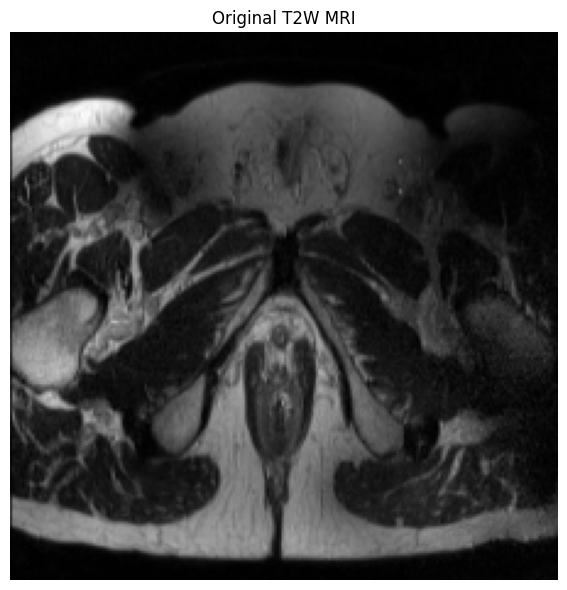


Creating EnsembleWithECA...

Loading ResNet50 weights...
ResNet missing keys: 0
ResNet unexpected keys: 0

Loading Swin-T weights...
Swin-T missing keys: 0
Swin-T unexpected keys: 0

Loading DenseNet121 weights...
DenseNet missing keys: 0
DenseNet unexpected keys: 0

Total ensemble features: 3840
✅ Ensemble architecture created.

Loading trained ensemble checkpoint...

✅ Ensemble checkpoint loaded.

Model device: cuda:0

TESTING ENSEMBLE PREDICTION
Prediction shape: (1, 2)
Prediction: [[1.2516975e-05 9.9998748e-01]]

Non-Cancer probability: 0.000013
Cancer probability: 0.999987
Predicted class: Cancer

RUNNING LIME
Number of samples: 2000
Number of requested superpixels: 100
This can take several minutes...


  0%|          | 0/2000 [00:00<?, ?it/s]

Intercept 1.5035588471883912
Prediction_local [0.05257904]
Right: 1.2516975e-05
Intercept -0.503558847700869
Prediction_local [0.94742096]
Right: 0.9999875

✅ LIME explanation completed.
Actual number of superpixels: 91

Number of LIME local features: 91


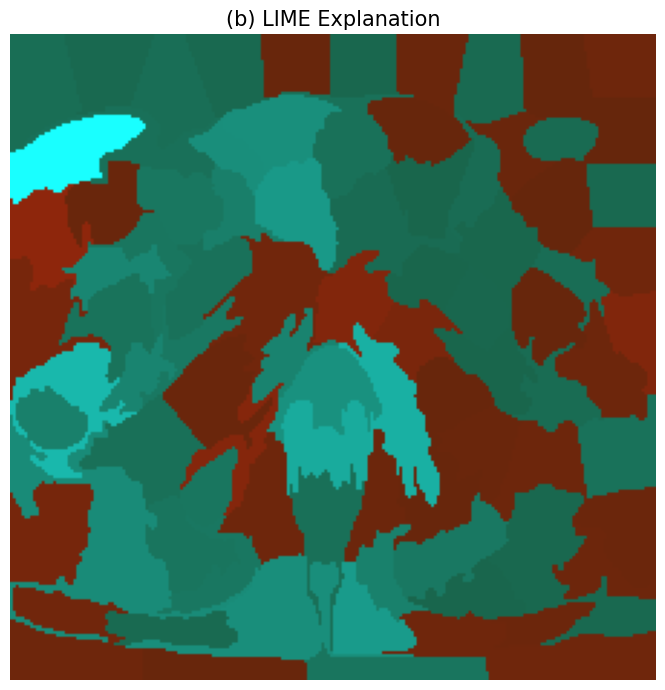

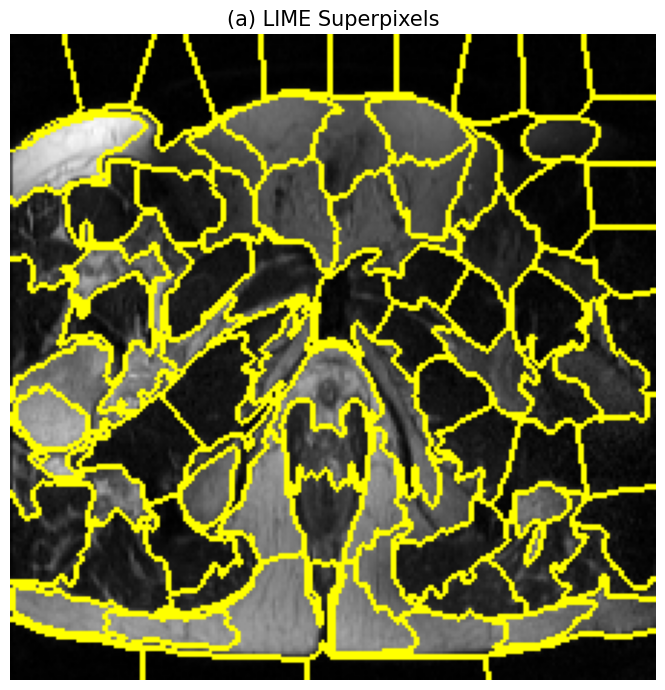

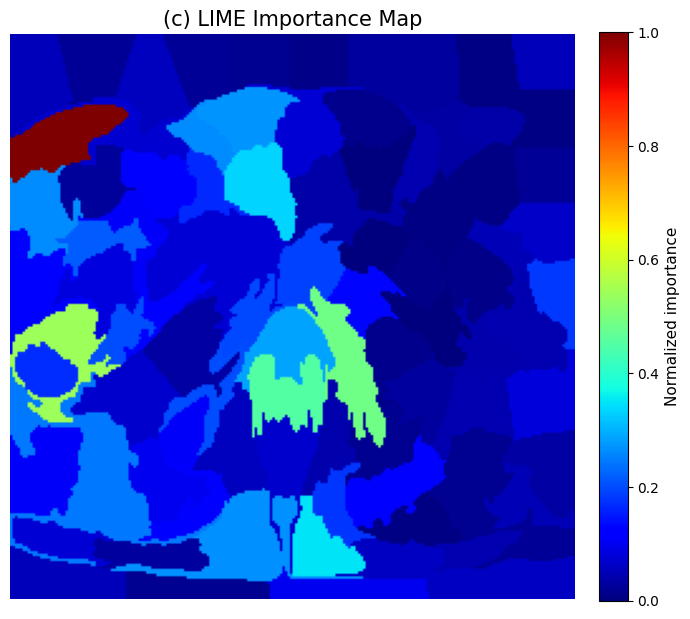

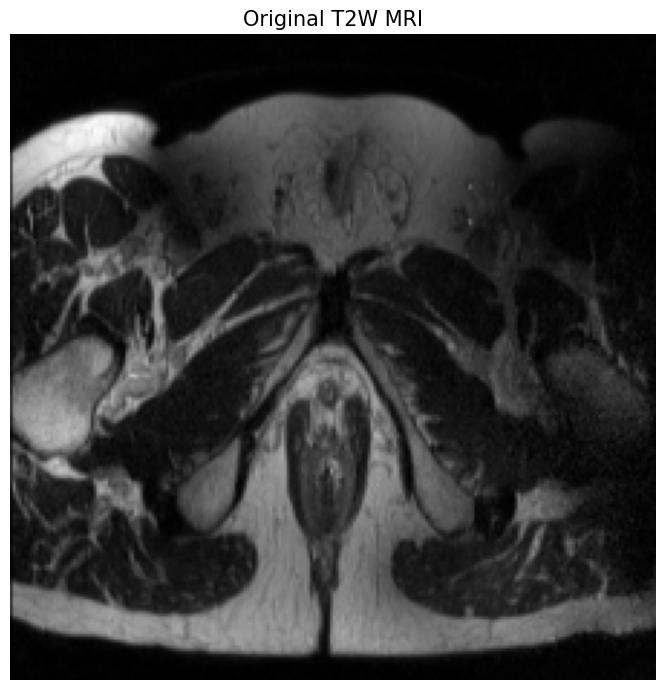

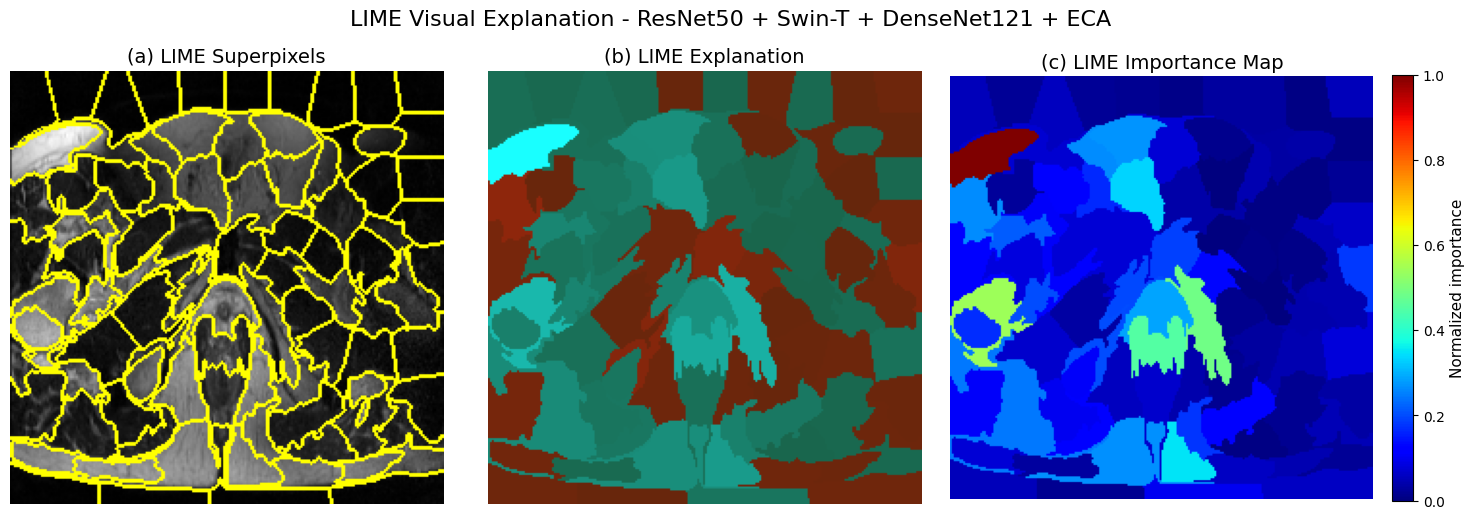


LIME ANALYSIS COMPLETE

MODEL
ResNet50 + Swin-T + DenseNet121 + ECA

PREDICTION
Non-Cancer: 0.0000
Cancer: 1.0000
Predicted class: Cancer

OUTPUT DIRECTORY
/content/drive/MyDrive/Classification/LIME_Ensemble

GENERATED FILES
1. /content/drive/MyDrive/Classification/LIME_Ensemble/Original_MRI.png
2. /content/drive/MyDrive/Classification/LIME_Ensemble/LIME_Superpixels.png
3. /content/drive/MyDrive/Classification/LIME_Ensemble/LIME_Explanation.png
4. /content/drive/MyDrive/Classification/LIME_Ensemble/LIME_Importance_Map.png
5. /content/drive/MyDrive/Classification/LIME_Ensemble/Figure_7_LIME_Ensemble.png
6. /content/drive/MyDrive/Classification/LIME_Ensemble/LIME_Importance_Map.npy
7. /content/drive/MyDrive/Classification/LIME_Ensemble/LIME_Segments.npy


In [16]:
# ================================================================
# LIME EXPLAINABILITY FOR:
#
# ResNet50 + Swin-T + DenseNet121 + ECA ENSEMBLE
#
# Output:
#   (a) LIME Superpixels
#   (b) LIME Explanation
#   (c) LIME Importance Map
#
# The complete ensemble is treated as a black-box classifier.
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import os
import random

import numpy as np
import matplotlib.pyplot as plt

import torch

from PIL import Image

from lime import lime_image

from skimage.segmentation import (
    slic,
    mark_boundaries
)


# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ================================================================
# 3. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("DEVICE")
print("=" * 70)
print("Using device:", device)
print("=" * 70)


# ================================================================
# 4. PATHS
# ================================================================

# ------------------------------------------------
# Individual pretrained model weights
# ------------------------------------------------

RESNET_PATH = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "ResNet_50/epoch_50_weights.pth"
)

SWINT_PATH = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Swin_Transformers/epoch_40_weights.pth"
)

DENSENET_PATH = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "DenseNet121/epoch_25_weights.pth"
)


# ------------------------------------------------
# Trained ensemble weights
# ------------------------------------------------

ENSEMBLE_PATH = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Ensemble/epoch_09_ensemble_weights.pth"
)


# ------------------------------------------------
# Test image
# ------------------------------------------------

IMAGE_PATH = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2/"
    "b_cancer/"
    "image17_804_.png"
)


# ------------------------------------------------
# Output directory
# ------------------------------------------------

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "Classification/"
    "LIME_Ensemble"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ================================================================
# 5. CHECK FILES
# ================================================================

paths_to_check = {
    "ResNet50 weights": RESNET_PATH,
    "Swin-T weights": SWINT_PATH,
    "DenseNet121 weights": DENSENET_PATH,
    "Ensemble weights": ENSEMBLE_PATH,
    "Test image": IMAGE_PATH
}


for name, path in paths_to_check.items():

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"\n{name} was not found:\n{path}"
        )

    print(f"✅ Found {name}")


# ================================================================
# 6. IMAGE CONFIGURATION
# ================================================================

IMAGE_SIZE = 224


# ================================================================
# 7. CLASS DEFINITIONS
# ================================================================
#
# Your ensemble ends with:
#
#     Linear(128, 1)
#     Sigmoid()
#
# Therefore:
#
#     output = probability of class 1
#
# We interpret:
#
#     class 0 = Non-Cancer
#     class 1 = Cancer
#
# If your training labels used the reverse convention,
# change these names.
#
# ================================================================

CLASS_NAMES = [
    "Non-Cancer",
    "Cancer"
]


# ================================================================
# 8. LOAD IMAGE
# ================================================================

def load_mri_image(
    image_path,
    image_size=224
):

    """
    Load MRI image as grayscale.

    Returns:
        H x W numpy array in [0,1]
    """

    image = Image.open(
        image_path
    ).convert(
        "L"
    )

    image = image.resize(
        (
            image_size,
            image_size
        ),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(
        image,
        dtype=np.float32
    )

    # ------------------------------------------------
    # Normalize image to [0,1]
    # ------------------------------------------------

    image_min = image.min()
    image_max = image.max()

    image = (
        image - image_min
    ) / (
        image_max - image_min + 1e-8
    )

    return image


# ================================================================
# 9. LOAD MRI
# ================================================================

gray_image = load_mri_image(
    IMAGE_PATH,
    IMAGE_SIZE
)

print(
    "\nImage shape:",
    gray_image.shape
)

print(
    "Image minimum:",
    gray_image.min()
)

print(
    "Image maximum:",
    gray_image.max()
)


# ================================================================
# 10. GRAYSCALE -> RGB
# ================================================================
#
# The three CNNs expect 3-channel input.
#
# Therefore:
#
#     grayscale -> R
#                 G
#                 B
#
# ================================================================

rgb_image = np.stack(
    [
        gray_image,
        gray_image,
        gray_image
    ],
    axis=-1
).astype(
    np.float32
)


print(
    "LIME input shape:",
    rgb_image.shape
)


# ================================================================
# 11. DISPLAY ORIGINAL IMAGE
# ================================================================

plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    gray_image,
    cmap="gray"
)

plt.title(
    "Original T2W MRI"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ================================================================
# 12. CREATE YOUR ACTUAL ENSEMBLE
# ================================================================
#
# IMPORTANT:
# These classes must already exist in your notebook:
#
#     ResNet50FeatureExtractor
#     SwinFeatureExtractor
#     DenseNetFeatureExtractor
#     ECALayer
#     EnsembleWithECA
#
# ================================================================

print(
    "\nCreating EnsembleWithECA..."
)


model = EnsembleWithECA(
    resnet_path=RESNET_PATH,
    swinT_path=SWINT_PATH,
    densenet_path=DENSENET_PATH
)


print(
    "✅ Ensemble architecture created."
)


# ================================================================
# 13. LOAD ENSEMBLE CHECKPOINT
# ================================================================

print(
    "\nLoading trained ensemble checkpoint..."
)


try:

    checkpoint = torch.load(
        ENSEMBLE_PATH,
        map_location="cpu",
        weights_only=True
    )

except TypeError:

    # For older PyTorch versions
    checkpoint = torch.load(
        ENSEMBLE_PATH,
        map_location="cpu"
    )


# ================================================================
# 14. HANDLE CHECKPOINT FORMAT
# ================================================================

if isinstance(
    checkpoint,
    dict
):

    if "state_dict" in checkpoint:

        checkpoint = checkpoint[
            "state_dict"
        ]

    elif "model_state_dict" in checkpoint:

        checkpoint = checkpoint[
            "model_state_dict"
        ]


# ================================================================
# 15. REMOVE module. PREFIX IF PRESENT
# ================================================================

cleaned_state_dict = {}

for key, value in checkpoint.items():

    new_key = key

    if new_key.startswith(
        "module."
    ):

        new_key = new_key[
            len("module.") :
        ]

    cleaned_state_dict[
        new_key
    ] = value


# ================================================================
# 16. LOAD ENSEMBLE WEIGHTS
# ================================================================

missing_keys, unexpected_keys = (
    model.load_state_dict(
        cleaned_state_dict,
        strict=False
    )
)


print(
    "\n✅ Ensemble checkpoint loaded."
)


if len(missing_keys) > 0:

    print(
        "\nMissing keys:"
    )

    for key in missing_keys:

        print(
            "   ",
            key
        )


if len(unexpected_keys) > 0:

    print(
        "\nUnexpected keys:"
    )

    for key in unexpected_keys:

        print(
            "   ",
            key
        )


# ================================================================
# 17. MOVE MODEL TO DEVICE
# ================================================================

model = model.to(
    device
)

model.eval()


# ================================================================
# 18. VERIFY MODEL DEVICE
# ================================================================

model_device = next(
    model.parameters()
).device


print(
    "\nModel device:",
    model_device
)


# ================================================================
# 19. IMAGE NET NORMALIZATION
# ================================================================
#
# IMPORTANT:
#
# Everything is moved to the SAME device.
#
# This fixes your:
#
# RuntimeError:
# Expected all tensors to be on the same device,
# but found cuda:0 and cpu
#
# ================================================================

IMAGENET_MEAN = torch.tensor(
    [
        0.485,
        0.456,
        0.406
    ],
    dtype=torch.float32
)


IMAGENET_STD = torch.tensor(
    [
        0.229,
        0.224,
        0.225
    ],
    dtype=torch.float32
)


# ================================================================
# 20. PREPROCESS FUNCTION
# ================================================================

def preprocess_for_model(
    image
):

    """
    Convert LIME image:

        H x W x 3

    into:

        1 x 3 x H x W

    and move everything to the correct device.
    """

    # ------------------------------------------------
    # NumPy float32
    # ------------------------------------------------

    image = np.asarray(
        image,
        dtype=np.float32
    )


    # ------------------------------------------------
    # Ensure [0,1]
    # ------------------------------------------------

    image = np.clip(
        image,
        0.0,
        1.0
    )


    # ------------------------------------------------
    # NumPy -> Tensor
    #
    # H x W x C
    # ->
    # C x H x W
    # ------------------------------------------------

    tensor = torch.from_numpy(
        image
    ).float()


    tensor = tensor.permute(
        2,
        0,
        1
    )


    # ------------------------------------------------
    # Add batch dimension
    #
    # C x H x W
    # ->
    # 1 x C x H x W
    # ------------------------------------------------

    tensor = tensor.unsqueeze(
        0
    )


    # ============================================================
    # VERY IMPORTANT
    #
    # MOVE INPUT TO DEVICE BEFORE NORMALIZATION
    # ============================================================

    tensor = tensor.to(
        device
    )


    # ------------------------------------------------
    # Move mean/std to SAME device
    # ------------------------------------------------

    mean = (
        IMAGENET_MEAN
        .to(device)
        .view(1, 3, 1, 1)
    )


    std = (
        IMAGENET_STD
        .to(device)
        .view(1, 3, 1, 1)
    )


    # ------------------------------------------------
    # ImageNet normalization
    # ------------------------------------------------

    tensor = (
        tensor - mean
    ) / std


    return tensor


# ================================================================
# 21. LIME PREDICTION FUNCTION
# ================================================================
#
# THIS FUNCTION IS DESIGNED SPECIFICALLY FOR YOUR MODEL.
#
# Your model outputs:
#
#     [batch, 1]
#
# and because the classifier ends with Sigmoid():
#
#     output = P(Cancer)
#
# We convert it to:
#
#     P(Non-Cancer) = 1 - P(Cancer)
#     P(Cancer)     = P(Cancer)
#
# LIME therefore receives:
#
#     [P(Non-Cancer), P(Cancer)]
#
# ================================================================

def predict_fn(
    images
):

    """
    Parameters
    ----------
    images:
        N x H x W x 3 numpy array

    Returns
    -------
    probabilities:
        N x 2 numpy array

        column 0 = Non-Cancer
        column 1 = Cancer
    """

    model.eval()


    predictions = []


    # ------------------------------------------------
    # Batch size for LIME predictions
    # ------------------------------------------------

    BATCH_SIZE = 32


    # ============================================================
    # PROCESS LIME IMAGES
    # ============================================================

    for start in range(
        0,
        len(images),
        BATCH_SIZE
    ):

        end = min(
            start + BATCH_SIZE,
            len(images)
        )


        current_images = images[
            start:end
        ]


        tensors = []


        # --------------------------------------------------------
        # Preprocess images
        # --------------------------------------------------------

        for image in current_images:

            tensor = preprocess_for_model(
                image
            )

            tensors.append(
                tensor
            )


        # --------------------------------------------------------
        # Concatenate
        #
        # Each tensor:
        #     1 x 3 x H x W
        #
        # Final:
        #     B x 3 x H x W
        # --------------------------------------------------------

        batch_tensor = torch.cat(
            tensors,
            dim=0
        )


        # --------------------------------------------------------
        # Safety:
        # ensure input is on same device as model
        # --------------------------------------------------------

        batch_tensor = batch_tensor.to(
            device
        )


        # ========================================================
        # MODEL PREDICTION
        # ========================================================

        with torch.no_grad():

            output = model(
                batch_tensor
            )


        # ========================================================
        # OUTPUT:
        #
        # B x 1
        #
        # because:
        #
        # Linear(128,1)
        # Sigmoid()
        # ========================================================

        cancer_probability = (
            output
            .reshape(-1)
            .detach()
            .cpu()
            .numpy()
        )


        # --------------------------------------------------------
        # Ensure [0,1]
        # --------------------------------------------------------

        cancer_probability = np.clip(
            cancer_probability,
            0.0,
            1.0
        )


        # --------------------------------------------------------
        # Binary complementary probability
        # --------------------------------------------------------

        non_cancer_probability = (
            1.0 - cancer_probability
        )


        # ========================================================
        # LIME FORMAT:
        #
        # [Non-Cancer, Cancer]
        # ========================================================

        batch_prediction = np.column_stack(
            [
                non_cancer_probability,
                cancer_probability
            ]
        )


        predictions.append(
            batch_prediction
        )


    # ============================================================
    # COMBINE ALL BATCHES
    # ============================================================

    predictions = np.concatenate(
        predictions,
        axis=0
    )


    return predictions


# ================================================================
# 22. TEST PREDICTION FUNCTION
# ================================================================
#
# DO THIS BEFORE RUNNING LIME.
#
# ================================================================

print(
    "\n" + "=" * 70
)

print(
    "TESTING ENSEMBLE PREDICTION"
)

print(
    "=" * 70
)


test_input = (
    rgb_image[
        np.newaxis,
        ...
    ]
)


prediction = predict_fn(
    test_input
)


print(
    "Prediction shape:",
    prediction.shape
)

print(
    "Prediction:",
    prediction
)


# ================================================================
# 23. CHECK PREDICTION
# ================================================================

if prediction.shape != (
    1,
    2
):

    raise RuntimeError(
        "Unexpected prediction shape. "
        f"Expected (1,2), got {prediction.shape}"
    )


non_cancer_probability = (
    prediction[0, 0]
)


cancer_probability = (
    prediction[0, 1]
)


predicted_class = int(
    np.argmax(
        prediction[0]
    )
)


predicted_class_name = (
    CLASS_NAMES[
        predicted_class
    ]
)


print(
    "\nNon-Cancer probability:",
    f"{non_cancer_probability:.6f}"
)

print(
    "Cancer probability:",
    f"{cancer_probability:.6f}"
)

print(
    "Predicted class:",
    predicted_class_name
)


# ================================================================
# 24. CREATE LIME EXPLAINER
# ================================================================

explainer = lime_image.LimeImageExplainer(
    verbose=True
)


# ================================================================
# 25. SLIC SEGMENTATION
# ================================================================
#
# These parameters determine the number/shape of superpixels.
#
# ================================================================

N_SEGMENTS = 100

COMPACTNESS = 10

SIGMA = 1


def segmentation_fn(
    image
):

    segments = slic(

        image,

        n_segments=N_SEGMENTS,

        compactness=COMPACTNESS,

        sigma=SIGMA,

        start_label=0,

        channel_axis=-1
    )

    return segments


# ================================================================
# 26. LIME SETTINGS
# ================================================================

NUM_SAMPLES = 2000

NUM_FEATURES = 15


# ================================================================
# 27. RUN LIME
# ================================================================

print(
    "\n" + "=" * 70
)

print(
    "RUNNING LIME"
)

print(
    "=" * 70
)

print(
    "Number of samples:",
    NUM_SAMPLES
)

print(
    "Number of requested superpixels:",
    N_SEGMENTS
)

print(
    "This can take several minutes..."
)


explanation = (
    explainer.explain_instance(

        rgb_image,

        classifier_fn=predict_fn,

        top_labels=2,

        hide_color=0,

        num_samples=NUM_SAMPLES,

        segmentation_fn=segmentation_fn,

        random_seed=SEED
    )
)


print(
    "\n✅ LIME explanation completed."
)


# ================================================================
# 28. GET SUPERPIXEL MAP
# ================================================================

segments = (
    explanation.segments
)


unique_segments = np.unique(
    segments
)


print(
    "Actual number of superpixels:",
    len(unique_segments)
)


# ================================================================
# 29. PANEL (A):
#     LIME SUPERPIXELS
# ================================================================

superpixel_image = mark_boundaries(

    rgb_image,

    segments,

    color=(1.0, 1.0, 0.0),

    mode="outer"
)


# ================================================================
# 30. GET LIME LOCAL EXPLANATION
# ================================================================
#
# explanation.local_exp[class_id]
#
# gives:
#
#     [(superpixel_id, weight), ...]
#
# Positive weight:
#     supports predicted class
#
# Negative weight:
#     opposes predicted class
#
# ================================================================

local_explanation = (
    explanation.local_exp[
        predicted_class
    ]
)


print(
    "\nNumber of LIME local features:",
    len(local_explanation)
)


# ================================================================
# 31. CREATE SIGNED IMPORTANCE MAP
# ================================================================

signed_importance = np.zeros(
    segments.shape,
    dtype=np.float32
)


for segment_id, weight in local_explanation:

    signed_importance[
        segments == segment_id
    ] = weight


# ================================================================
# 32. NORMALIZE SIGNED MAP TO [-1,1]
# ================================================================

max_abs = np.max(
    np.abs(
        signed_importance
    )
)


if max_abs > 1e-12:

    signed_normalized = (
        signed_importance /
        max_abs
    )

else:

    signed_normalized = (
        signed_importance
    )


signed_normalized = np.clip(
    signed_normalized,
    -1.0,
    1.0
)


# ================================================================
# 33. ABSOLUTE IMPORTANCE MAP [0,1]
# ================================================================
#
# This corresponds to Figure 7(c).
#
#     0 = no/little contribution
#     1 = strongest contribution
#
# ================================================================

importance_map = np.abs(
    signed_normalized
)


importance_map = np.clip(
    importance_map,
    0.0,
    1.0
)


# ================================================================
# 34. CREATE CUSTOM LIME EXPLANATION MAP
# ================================================================
#
# We explicitly create:
#
#     positive -> green/cyan
#     negative -> red/brown
#     zero     -> black
#
# to match the description of Figure 7.
#
# ================================================================

explanation_rgb = np.zeros(
    (
        segments.shape[0],
        segments.shape[1],
        3
    ),
    dtype=np.float32
)


# ------------------------------------------------
# Positive evidence
# ------------------------------------------------
#
# Green/cyan
# ------------------------------------------------

positive_mask = (
    signed_normalized > 0
)


positive_strength = np.clip(
    signed_normalized,
    0,
    1
)


explanation_rgb[
    positive_mask,
    0
] = (
    0.1
)

explanation_rgb[
    positive_mask,
    1
] = (
    0.4 +
    0.6 *
    positive_strength[
        positive_mask
    ]
)

explanation_rgb[
    positive_mask,
    2
] = (
    0.3 +
    0.7 *
    positive_strength[
        positive_mask
    ]
)


# ------------------------------------------------
# Negative evidence
# ------------------------------------------------
#
# Red/brown
# ------------------------------------------------

negative_mask = (
    signed_normalized < 0
)


negative_strength = np.clip(
    -signed_normalized,
    0,
    1
)


explanation_rgb[
    negative_mask,
    0
] = (
    0.4 +
    0.6 *
    negative_strength[
        negative_mask
    ]
)

explanation_rgb[
    negative_mask,
    1
] = (
    0.15
)

explanation_rgb[
    negative_mask,
    2
] = (
    0.05
)


# ================================================================
# 35. PANEL (B)
#     LIME EXPLANATION
# ================================================================

explanation_output = os.path.join(
    OUTPUT_DIR,
    "LIME_Explanation.png"
)


plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    explanation_rgb
)

plt.title(
    "(b) LIME Explanation",
    fontsize=15
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.savefig(
    explanation_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 36. PANEL (A) SAVE
# ================================================================

superpixel_output = os.path.join(
    OUTPUT_DIR,
    "LIME_Superpixels.png"
)


plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    superpixel_image
)

plt.title(
    "(a) LIME Superpixels",
    fontsize=15
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.savefig(
    superpixel_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 37. PANEL (C)
#     LIME IMPORTANCE MAP
# ================================================================

importance_output = os.path.join(
    OUTPUT_DIR,
    "LIME_Importance_Map.png"
)


plt.figure(
    figsize=(7, 7)
)

image_handle = plt.imshow(

    importance_map,

    cmap="jet",

    vmin=0,

    vmax=1
)


plt.title(
    "(c) LIME Importance Map",
    fontsize=15
)

plt.axis(
    "off"
)


colorbar = plt.colorbar(
    image_handle,
    fraction=0.046,
    pad=0.04
)


colorbar.set_label(
    "Normalized importance",
    fontsize=11
)


plt.tight_layout()

plt.savefig(
    importance_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 38. ORIGINAL IMAGE
# ================================================================

original_output = os.path.join(
    OUTPUT_DIR,
    "Original_MRI.png"
)


plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    gray_image,
    cmap="gray"
)

plt.title(
    "Original T2W MRI",
    fontsize=15
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.savefig(
    original_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 39. CREATE FINAL FIGURE 7
# ================================================================

figure7_output = os.path.join(
    OUTPUT_DIR,
    "Figure_7_LIME_Ensemble.png"
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


# ================================================================
# PANEL A
# ================================================================

axes[0].imshow(
    superpixel_image
)

axes[0].set_title(
    "(a) LIME Superpixels",
    fontsize=14
)

axes[0].axis(
    "off"
)


# ================================================================
# PANEL B
# ================================================================

axes[1].imshow(
    explanation_rgb
)

axes[1].set_title(
    "(b) LIME Explanation",
    fontsize=14
)

axes[1].axis(
    "off"
)


# ================================================================
# PANEL C
# ================================================================

heatmap_handle = axes[2].imshow(

    importance_map,

    cmap="jet",

    vmin=0,

    vmax=1
)

axes[2].set_title(
    "(c) LIME Importance Map",
    fontsize=14
)

axes[2].axis(
    "off"
)


# ================================================================
# COLORBAR
# ================================================================

cbar = fig.colorbar(

    heatmap_handle,

    ax=axes[2],

    fraction=0.046,

    pad=0.04
)


cbar.set_label(
    "Normalized importance",
    fontsize=11
)


# ================================================================
# OVERALL TITLE
# ================================================================

fig.suptitle(

    "LIME Visual Explanation - "
    "ResNet50 + Swin-T + DenseNet121 + ECA",

    fontsize=16,

    y=1.02
)


plt.tight_layout()


plt.savefig(

    figure7_output,

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 40. SAVE NUMERICAL IMPORTANCE MAP
# ================================================================

importance_npy_path = os.path.join(
    OUTPUT_DIR,
    "LIME_Importance_Map.npy"
)


np.save(
    importance_npy_path,
    importance_map
)


# ================================================================
# 41. SAVE SEGMENTATION MAP
# ================================================================

segments_npy_path = os.path.join(
    OUTPUT_DIR,
    "LIME_Segments.npy"
)


np.save(
    segments_npy_path,
    segments
)


# ================================================================
# 42. FINAL SUMMARY
# ================================================================

print(
    "\n" + "=" * 70
)

print(
    "LIME ANALYSIS COMPLETE"
)

print(
    "=" * 70
)

print(
    "\nMODEL"
)

print(
    "ResNet50 + Swin-T + DenseNet121 + ECA"
)


print(
    "\nPREDICTION"
)

print(
    "Non-Cancer:",
    f"{non_cancer_probability:.4f}"
)

print(
    "Cancer:",
    f"{cancer_probability:.4f}"
)

print(
    "Predicted class:",
    predicted_class_name
)


print(
    "\nOUTPUT DIRECTORY"
)

print(
    OUTPUT_DIR
)


print(
    "\nGENERATED FILES"
)

print(
    "1.",
    original_output
)

print(
    "2.",
    superpixel_output
)

print(
    "3.",
    explanation_output
)

print(
    "4.",
    importance_output
)

print(
    "5.",
    figure7_output
)

print(
    "6.",
    importance_npy_path
)

print(
    "7.",
    segments_npy_path
)

print(
    "=" * 70
)

In [17]:
#Occlusion Sensitivity

Device: cuda
Model device: cuda:0
Image shape: (224, 224, 3)

Baseline cancer probability: 0.999987

Baseline probability: 0.999987
Total occlusion patches: 784

Running occlusion analysis...
Processed 784/784 patches

Occlusion analysis complete.

Sensitivity statistics:
Minimum: -8.970499e-06
Maximum: 0.0003580451
Mean: 3.565787e-06


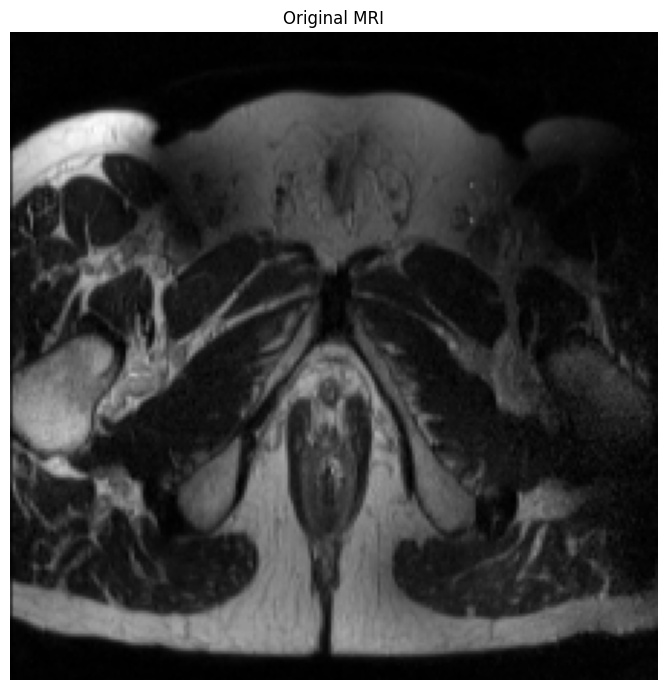

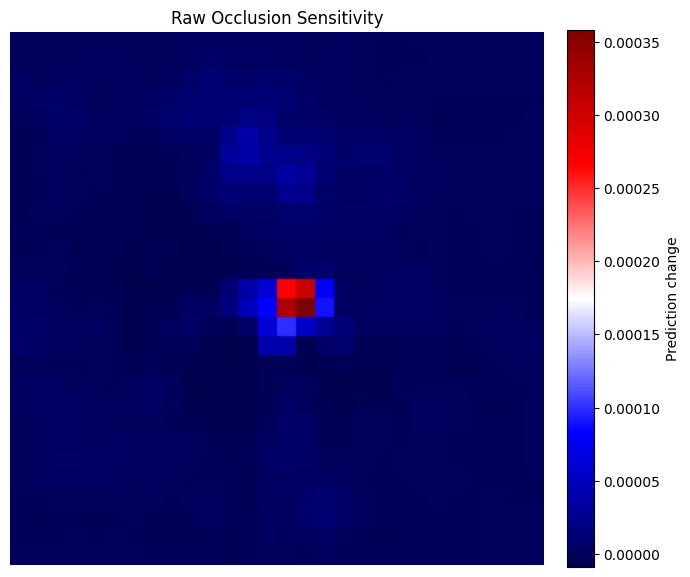

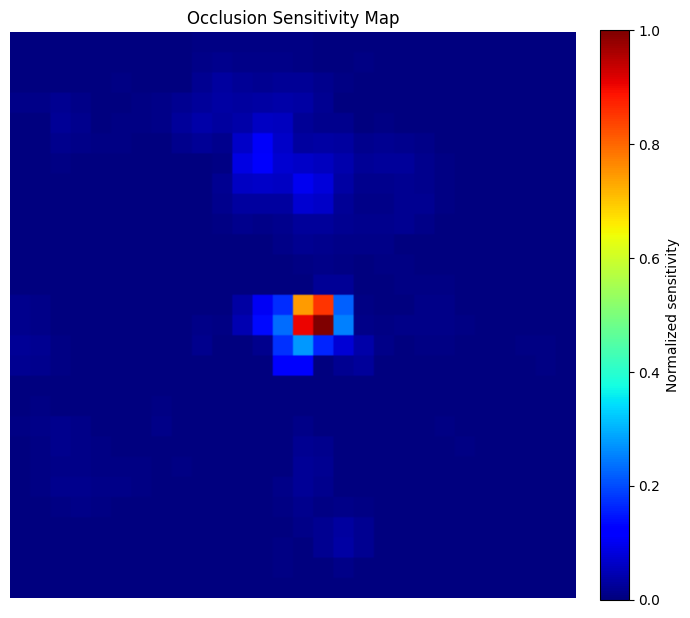

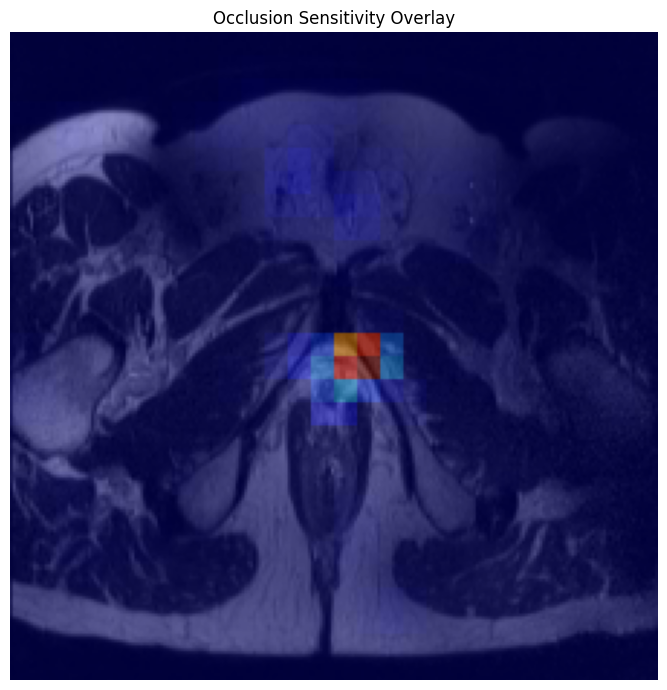

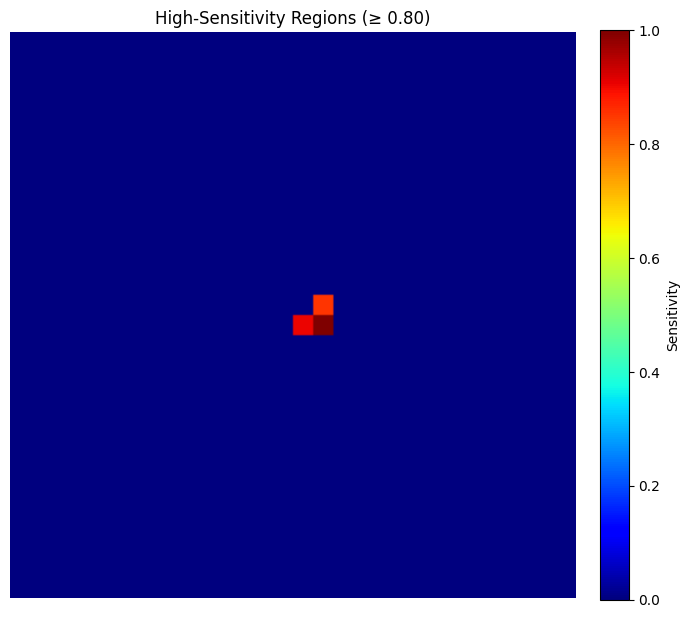

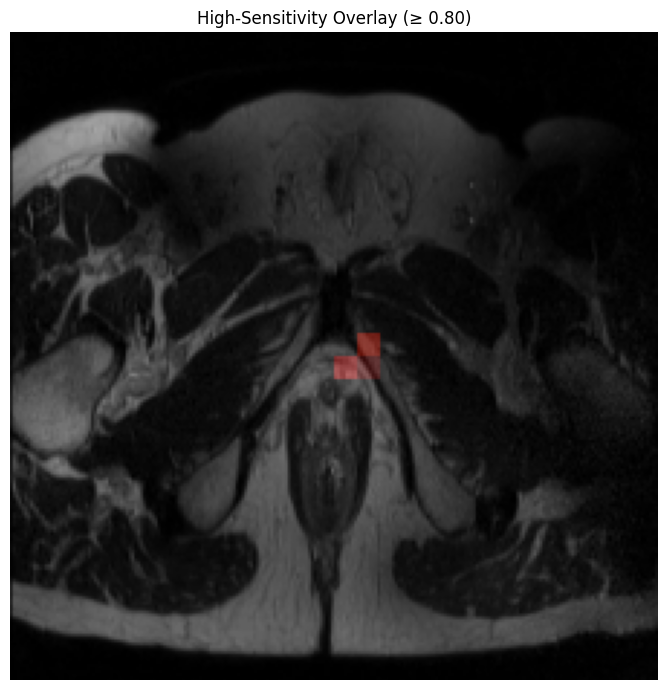

/tmp/ipykernel_8085/3773695220.py:1237: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


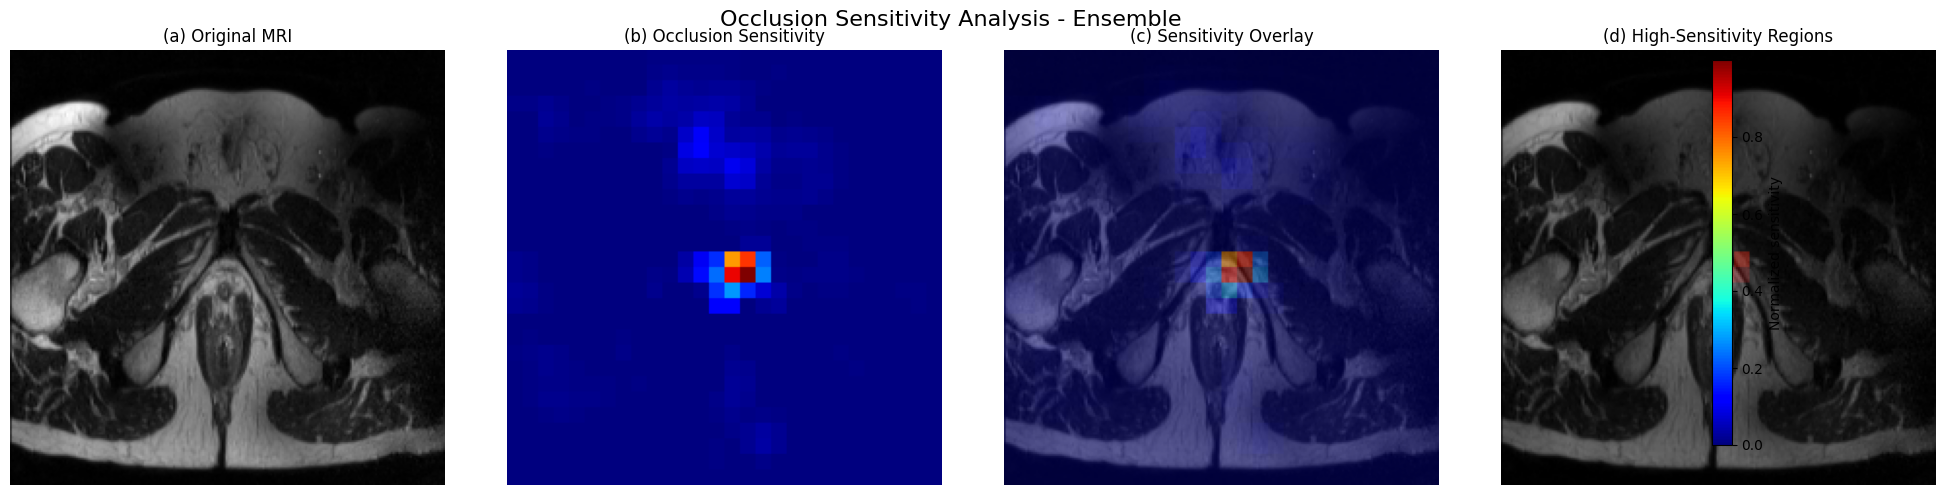


OCCLUSION SENSITIVITY ANALYSIS COMPLETE

Baseline cancer probability: 0.999987
Maximum sensitivity: 0.000358
Minimum sensitivity: -0.000009
Mean sensitivity: 0.000004

High-sensitivity threshold: 0.8
High-sensitivity pixels: 0.38%

Output files:
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/Occlusion_Sensitivity_Raw.npy
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/Occlusion_Sensitivity_Normalized.npy
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/Occlusion_Sensitivity_Heatmap.png
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/Occlusion_Sensitivity_Overlay.png
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/High_Sensitivity_Map.npy
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/High_Sensitivity_Heatmap.png
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/High_Sensitivity_Overlay.png
/content/drive/MyDrive/Classification/Occlusion_Sensitivity/High_Sensitivity_Transparent.png
/content/drive/MyDrive

In [19]:
# ================================================================
# OCCLUSION SENSITIVITY ANALYSIS
#
# Model:
# ResNet50 + Swin-T + DenseNet121 + ECA
#
# Outputs:
#
# 1. Original MRI
# 2. Raw occlusion sensitivity map
# 3. Colored sensitivity heatmap
# 4. Heatmap overlay
# 5. High-sensitivity map
# 6. High-sensitivity overlay
#
# ================================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image


# ================================================================
# 1. SETTINGS
# ================================================================

IMAGE_PATH = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2/"
    "b_cancer/"
    "image17_804_.png"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Occlusion_Sensitivity"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ================================================================
# 2. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)
model.eval()

print("Device:", device)
print(
    "Model device:",
    next(model.parameters()).device
)


# ================================================================
# 3. IMAGE SIZE
# ================================================================

IMAGE_SIZE = 224


# ================================================================
# 4. LOAD MRI
# ================================================================

def load_mri_image(
    image_path,
    image_size=224
):

    image = Image.open(
        image_path
    ).convert("L")

    image = image.resize(
        (
            image_size,
            image_size
        ),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(
        image,
        dtype=np.float32
    )

    # Normalize to [0,1]
    image_min = image.min()
    image_max = image.max()

    image = (
        image - image_min
    ) / (
        image_max - image_min + 1e-8
    )

    return image


gray_image = load_mri_image(
    IMAGE_PATH,
    IMAGE_SIZE
)


# ================================================================
# 5. GRAYSCALE -> RGB
# ================================================================

rgb_image = np.stack(
    [
        gray_image,
        gray_image,
        gray_image
    ],
    axis=-1
).astype(
    np.float32
)


print(
    "Image shape:",
    rgb_image.shape
)


# ================================================================
# 6. NORMALIZATION
# ================================================================

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
)


def preprocess_for_model(image):

    image = np.asarray(
        image,
        dtype=np.float32
    )

    image = np.clip(
        image,
        0.0,
        1.0
    )

    tensor = torch.from_numpy(
        image
    ).float()

    # H,W,C -> C,H,W
    tensor = tensor.permute(
        2,
        0,
        1
    )

    # C,H,W -> 1,C,H,W
    tensor = tensor.unsqueeze(
        0
    )

    # Move image to same device as model
    tensor = tensor.to(
        device
    )

    mean = (
        IMAGENET_MEAN
        .to(device)
        .view(1, 3, 1, 1)
    )

    std = (
        IMAGENET_STD
        .to(device)
        .view(1, 3, 1, 1)
    )

    tensor = (
        tensor - mean
    ) / std

    return tensor


# ================================================================
# 7. ENSEMBLE PREDICTION
# ================================================================

def get_prediction(
    image
):

    """
    Returns:

        cancer_probability

    Your ensemble has:

        Linear(..., 1)
        Sigmoid()

    Therefore model output is P(Cancer).
    """

    tensor = preprocess_for_model(
        image
    )

    model.eval()

    with torch.no_grad():

        output = model(
            tensor
        )

    cancer_probability = (
        output
        .reshape(-1)[0]
        .detach()
        .cpu()
        .item()
    )

    cancer_probability = float(
        np.clip(
            cancer_probability,
            0.0,
            1.0
        )
    )

    return cancer_probability


# ================================================================
# 8. BASELINE PREDICTION
# ================================================================

baseline_probability = get_prediction(
    rgb_image
)

print(
    "\nBaseline cancer probability:",
    f"{baseline_probability:.6f}"
)


# ================================================================
# 9. OCCLUSION FUNCTION
# ================================================================

def create_occluded_image(
    image,
    x,
    y,
    patch_size,
    occlusion_value=0.0
):

    """
    Occlude a square region.

    x = horizontal coordinate
    y = vertical coordinate

    occlusion_value = 0
    means black/dark occlusion.
    """

    occluded = image.copy()

    height, width, _ = (
        occluded.shape
    )

    x1 = max(
        0,
        x
    )

    y1 = max(
        0,
        y
    )

    x2 = min(
        width,
        x + patch_size
    )

    y2 = min(
        height,
        y + patch_size
    )

    occluded[
        y1:y2,
        x1:x2,
        :
    ] = occlusion_value

    return occluded


# ================================================================
# 10. OCCLUSION SENSITIVITY
# ================================================================

def calculate_occlusion_sensitivity(
    image,
    patch_size=16,
    stride=8,
    occlusion_value=0.0
):

    """
    Calculates:

        sensitivity =
            baseline_prediction
            -
            occluded_prediction

    Positive value:
        occluding the region reduces cancer probability.

        Therefore region supports cancer prediction.

    Large positive value:
        highly sensitive / important region.

    Negative value:
        occluding region increases cancer probability.
    """

    height, width, _ = (
        image.shape
    )

    # ------------------------------------------------
    # Store sensitivity at each pixel
    # ------------------------------------------------

    sensitivity_sum = np.zeros(
        (height, width),
        dtype=np.float32
    )

    sensitivity_count = np.zeros(
        (height, width),
        dtype=np.float32
    )

    # ------------------------------------------------
    # Baseline
    # ------------------------------------------------

    baseline = get_prediction(
        image
    )

    print(
        "\nBaseline probability:",
        f"{baseline:.6f}"
    )

    # ------------------------------------------------
    # Number of patches
    # ------------------------------------------------

    total_x = (
        len(
            range(
                0,
                width,
                stride
            )
        )
    )

    total_y = (
        len(
            range(
                0,
                height,
                stride
            )
        )
    )

    total_patches = (
        total_x *
        total_y
    )

    patch_counter = 0

    print(
        "Total occlusion patches:",
        total_patches
    )

    print(
        "\nRunning occlusion analysis..."
    )

    # ============================================================
    # SLIDING WINDOW
    # ============================================================

    for y in range(
        0,
        height,
        stride
    ):

        for x in range(
            0,
            width,
            stride
        ):

            patch_counter += 1

            # ----------------------------------------
            # Create occluded image
            # ----------------------------------------

            occluded = create_occluded_image(
                image=image,
                x=x,
                y=y,
                patch_size=patch_size,
                occlusion_value=occlusion_value
            )

            # ----------------------------------------
            # Prediction
            # ----------------------------------------

            occluded_probability = (
                get_prediction(
                    occluded
                )
            )

            # ----------------------------------------
            # Sensitivity
            #
            # Positive:
            # baseline > occluded
            #
            # Means region supports cancer.
            # ----------------------------------------

            sensitivity = (
                baseline -
                occluded_probability
            )

            # ----------------------------------------
            # Patch boundaries
            # ----------------------------------------

            x1 = x
            y1 = y

            x2 = min(
                width,
                x + patch_size
            )

            y2 = min(
                height,
                y + patch_size
            )

            # ----------------------------------------
            # Accumulate
            # ----------------------------------------

            sensitivity_sum[
                y1:y2,
                x1:x2
            ] += sensitivity

            sensitivity_count[
                y1:y2,
                x1:x2
            ] += 1.0

            # ----------------------------------------
            # Progress
            # ----------------------------------------

            if (
                patch_counter % 25 == 0
                or
                patch_counter == total_patches
            ):

                print(
                    f"\rProcessed "
                    f"{patch_counter}/"
                    f"{total_patches} patches",
                    end=""
                )

    print(
        "\n\nOcclusion analysis complete."
    )

    # ============================================================
    # AVERAGE OVERLAPPING PATCHES
    # ============================================================

    sensitivity_map = (
        sensitivity_sum /
        (
            sensitivity_count +
            1e-8
        )
    )

    return sensitivity_map


# ================================================================
# 11. RUN OCCLUSION
# ================================================================
#
# Recommended:
#
# patch_size = 16
# stride     = 8
#
# Smaller stride = smoother but slower.
#
# ================================================================

PATCH_SIZE = 16
STRIDE = 8

sensitivity_map = (
    calculate_occlusion_sensitivity(

        image=rgb_image,

        patch_size=PATCH_SIZE,

        stride=STRIDE,

        occlusion_value=0.0
    )
)


# ================================================================
# 12. RAW STATISTICS
# ================================================================

print(
    "\nSensitivity statistics:"
)

print(
    "Minimum:",
    sensitivity_map.min()
)

print(
    "Maximum:",
    sensitivity_map.max()
)

print(
    "Mean:",
    sensitivity_map.mean()
)


# ================================================================
# 13. NORMALIZE SENSITIVITY MAP
# ================================================================
#
# We normalize based on the positive sensitivity range.
#
# 0 = low sensitivity
# 1 = highest positive sensitivity
#
# ================================================================

positive_sensitivity = np.maximum(
    sensitivity_map,
    0
)

max_positive = (
    positive_sensitivity.max()
)

if max_positive > 1e-8:

    normalized_sensitivity = (
        positive_sensitivity /
        max_positive
    )

else:

    normalized_sensitivity = (
        np.zeros_like(
            positive_sensitivity
        )
    )


normalized_sensitivity = np.clip(
    normalized_sensitivity,
    0.0,
    1.0
)


# ================================================================
# 14. SAVE RAW DATA
# ================================================================

raw_npy_path = os.path.join(
    OUTPUT_DIR,
    "Occlusion_Sensitivity_Raw.npy"
)

normalized_npy_path = os.path.join(
    OUTPUT_DIR,
    "Occlusion_Sensitivity_Normalized.npy"
)

np.save(
    raw_npy_path,
    sensitivity_map
)

np.save(
    normalized_npy_path,
    normalized_sensitivity
)


# ================================================================
# 15. CREATE COLORED HEATMAP
# ================================================================

heatmap_uint8 = (
    normalized_sensitivity *
    255
).astype(
    np.uint8
)

heatmap_bgr = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_rgb = cv2.cvtColor(
    heatmap_bgr,
    cv2.COLOR_BGR2RGB
)


# ================================================================
# 16. SAVE HEATMAP ONLY
# ================================================================

heatmap_only_path = os.path.join(
    OUTPUT_DIR,
    "Occlusion_Sensitivity_Heatmap.png"
)

cv2.imwrite(
    heatmap_only_path,
    heatmap_bgr
)


# ================================================================
# 17. CREATE OVERLAY
# ================================================================

original_uint8 = (
    gray_image *
    255
).astype(
    np.uint8
)

original_rgb = cv2.cvtColor(
    original_uint8,
    cv2.COLOR_GRAY2RGB
)


# ------------------------------------------------
# Blend
# ------------------------------------------------

overlay = cv2.addWeighted(
    original_rgb,
    0.55,
    heatmap_rgb,
    0.45,
    0
)


# ================================================================
# 18. SAVE OVERLAY
# ================================================================

overlay_path = os.path.join(
    OUTPUT_DIR,
    "Occlusion_Sensitivity_Overlay.png"
)

cv2.imwrite(
    overlay_path,
    cv2.cvtColor(
        overlay,
        cv2.COLOR_RGB2BGR
    )
)


# ================================================================
# 19. HIGH-SENSITIVITY MASK
# ================================================================
#
# This is particularly useful for your analysis.
#
# For example:
#
# threshold = 0.80
#
# means only regions belonging to the
# highest 20% sensitivity range are retained.
#
# ================================================================

HIGH_SENSITIVITY_THRESHOLD = 0.80

high_sensitivity_mask = (
    normalized_sensitivity
    >= HIGH_SENSITIVITY_THRESHOLD
)


# ================================================================
# 20. HIGH-SENSITIVITY MAP
# ================================================================

high_sensitivity_map = (
    normalized_sensitivity *
    high_sensitivity_mask
)


# ================================================================
# 21. SAVE HIGH-SENSITIVITY NUMERICAL MAP
# ================================================================

high_map_npy_path = os.path.join(
    OUTPUT_DIR,
    "High_Sensitivity_Map.npy"
)

np.save(
    high_map_npy_path,
    high_sensitivity_map
)


# ================================================================
# 22. HIGH-SENSITIVITY HEATMAP
# ================================================================

high_heatmap_uint8 = (
    high_sensitivity_map *
    255
).astype(
    np.uint8
)

high_heatmap_bgr = cv2.applyColorMap(
    high_heatmap_uint8,
    cv2.COLORMAP_JET
)

high_heatmap_rgb = cv2.cvtColor(
    high_heatmap_bgr,
    cv2.COLOR_BGR2RGB
)


# ================================================================
# 23. REMOVE BACKGROUND FROM HIGH-SENSITIVITY MAP
# ================================================================
#
# Pixels below threshold become black.
#
# ================================================================

high_heatmap_rgb[
    ~high_sensitivity_mask
] = 0


# ================================================================
# 24. SAVE HIGH-SENSITIVITY HEATMAP
# ================================================================

high_heatmap_path = os.path.join(
    OUTPUT_DIR,
    "High_Sensitivity_Heatmap.png"
)

cv2.imwrite(
    high_heatmap_path,
    cv2.cvtColor(
        high_heatmap_rgb,
        cv2.COLOR_RGB2BGR
    )
)


# ================================================================
# 25. HIGH-SENSITIVITY OVERLAY
# ================================================================

high_overlay = (
    original_rgb.astype(
        np.float32
    ) * 0.65
    +
    high_heatmap_rgb.astype(
        np.float32
    ) * 0.35
)

high_overlay = np.clip(
    high_overlay,
    0,
    255
).astype(
    np.uint8
)


# ================================================================
# 26. SAVE HIGH-SENSITIVITY OVERLAY
# ================================================================

high_overlay_path = os.path.join(
    OUTPUT_DIR,
    "High_Sensitivity_Overlay.png"
)

cv2.imwrite(
    high_overlay_path,
    cv2.cvtColor(
        high_overlay,
        cv2.COLOR_RGB2BGR
    )
)


# ================================================================
# 27. CREATE TRANSPARENT HIGH-SENSITIVITY OVERLAY
# ================================================================
#
# This makes it easier to see exactly where
# the model is sensitive.
#
# ================================================================

transparent_overlay = np.zeros(
    (
        IMAGE_SIZE,
        IMAGE_SIZE,
        4
    ),
    dtype=np.uint8
)

transparent_overlay[:, :, :3] = (
    high_heatmap_rgb
)

transparent_overlay[:, :, 3] = (
    high_sensitivity_mask.astype(
        np.uint8
    ) * 220
)


transparent_overlay_path = os.path.join(
    OUTPUT_DIR,
    "High_Sensitivity_Transparent.png"
)


Image.fromarray(
    transparent_overlay
).save(
    transparent_overlay_path
)


# ================================================================
# 28. DISPLAY ORIGINAL
# ================================================================

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    gray_image,
    cmap="gray"
)

plt.title(
    "Original MRI"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ================================================================
# 29. DISPLAY RAW SENSITIVITY
# ================================================================

plt.figure(
    figsize=(7, 7)
)

im = plt.imshow(
    sensitivity_map,
    cmap="seismic"
)

plt.title(
    "Raw Occlusion Sensitivity"
)

plt.axis(
    "off"
)

plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    label="Prediction change"
)

plt.tight_layout()

plt.show()


# ================================================================
# 30. DISPLAY NORMALIZED HEATMAP
# ================================================================

plt.figure(
    figsize=(7, 7)
)

im = plt.imshow(
    normalized_sensitivity,
    cmap="jet",
    vmin=0,
    vmax=1
)

plt.title(
    "Occlusion Sensitivity Map"
)

plt.axis(
    "off"
)

plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    label="Normalized sensitivity"
)

plt.tight_layout()

plt.show()


# ================================================================
# 31. DISPLAY OVERLAY
# ================================================================

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    overlay
)

plt.title(
    "Occlusion Sensitivity Overlay"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ================================================================
# 32. DISPLAY HIGH-SENSITIVITY MAP
# ================================================================

plt.figure(
    figsize=(7, 7)
)

im = plt.imshow(
    high_sensitivity_map,
    cmap="jet",
    vmin=0,
    vmax=1
)

plt.title(
    f"High-Sensitivity Regions "
    f"(≥ {HIGH_SENSITIVITY_THRESHOLD:.2f})"
)

plt.axis(
    "off"
)

plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    label="Sensitivity"
)

plt.tight_layout()

plt.show()


# ================================================================
# 33. DISPLAY HIGH-SENSITIVITY OVERLAY
# ================================================================

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    high_overlay
)

plt.title(
    f"High-Sensitivity Overlay "
    f"(≥ {HIGH_SENSITIVITY_THRESHOLD:.2f})"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ================================================================
# 34. CREATE FINAL COMPARISON FIGURE
# ================================================================

comparison_path = os.path.join(
    OUTPUT_DIR,
    "Occlusion_Sensitivity_Analysis.png"
)


fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)


# ------------------------------------------------
# Original
# ------------------------------------------------

axes[0].imshow(
    gray_image,
    cmap="gray"
)

axes[0].set_title(
    "(a) Original MRI"
)

axes[0].axis(
    "off"
)


# ------------------------------------------------
# Sensitivity
# ------------------------------------------------

im1 = axes[1].imshow(
    normalized_sensitivity,
    cmap="jet",
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "(b) Occlusion Sensitivity"
)

axes[1].axis(
    "off"
)


# ------------------------------------------------
# Overlay
# ------------------------------------------------

axes[2].imshow(
    overlay
)

axes[2].set_title(
    "(c) Sensitivity Overlay"
)

axes[2].axis(
    "off"
)


# ------------------------------------------------
# High sensitivity
# ------------------------------------------------

axes[3].imshow(
    high_overlay
)

axes[3].set_title(
    "(d) High-Sensitivity Regions"
)

axes[3].axis(
    "off"
)


# ------------------------------------------------
# Colorbar
# ------------------------------------------------

fig.colorbar(
    im1,
    ax=axes,
    fraction=0.025,
    pad=0.02,
    label="Normalized sensitivity"
)


plt.suptitle(
    "Occlusion Sensitivity Analysis - Ensemble",
    fontsize=16
)

plt.tight_layout()


plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 35. QUANTIFY HIGH-SENSITIVITY AREA
# ================================================================

high_pixel_percentage = (
    high_sensitivity_mask.mean()
    * 100
)


print(
    "\n" + "=" * 70
)

print(
    "OCCLUSION SENSITIVITY ANALYSIS COMPLETE"
)

print(
    "=" * 70
)

print(
    "\nBaseline cancer probability:",
    f"{baseline_probability:.6f}"
)

print(
    "Maximum sensitivity:",
    f"{sensitivity_map.max():.6f}"
)

print(
    "Minimum sensitivity:",
    f"{sensitivity_map.min():.6f}"
)

print(
    "Mean sensitivity:",
    f"{sensitivity_map.mean():.6f}"
)

print(
    "\nHigh-sensitivity threshold:",
    HIGH_SENSITIVITY_THRESHOLD
)

print(
    "High-sensitivity pixels:",
    f"{high_pixel_percentage:.2f}%"
)


print(
    "\nOutput files:"
)

print(
    raw_npy_path
)

print(
    normalized_npy_path
)

print(
    heatmap_only_path
)

print(
    overlay_path
)

print(
    high_map_npy_path
)

print(
    high_heatmap_path
)

print(
    high_overlay_path
)

print(
    transparent_overlay_path
)

print(
    comparison_path
)

print(
    "=" * 70
)